In [ ]:
from P2D import P2D
import seaborn as sns
import matplotlib.pyplot as plt
# Set a single font size for everything
fontsize = 15

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "font.size": fontsize,          # Base font size for everything
        "axes.titlesize": fontsize,     # Axes title
        "axes.labelsize": fontsize,     # Axes labels
        "xtick.labelsize": fontsize,    # X ticks
        "ytick.labelsize": fontsize/1.5,    # Y ticks
        "legend.fontsize": fontsize,    # Legend text
        "figure.titlesize": fontsize,   # Figure title
        "figure.dpi": 100              # Figure quality
    }
)


#timerange=['2008-1-1', '2010-2-01']
#timerange=['2010-1-1', '2012-2-01']
#timerange=['2012-1-1', '2014-2-01']
#timerange=['2014-1-1', '2016-2-01']
#timerange=['2016-1-1', '2018-2-01']
#timerange=['2018-1-1', '2020-2-01']
timerange=['2020-1-1', '2022-2-01']
#timerange=['2022-1-1', '2024-2-01']
#timerange=['2024-1-1', '2026-1-01']



model1 = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'PSP', 'SolO']
                , timerange=timerange
                , propagation_time='5d'
                , model_type='inelastic'
                , degree_resolution=0.5
                , smooth = '1d'
                , seperate_models=False

)

model1.movie(time_window='28d', variable_to_plot='V', cadence='12h', frametrate=30, name='LONGMOVIE7', observers=['OMNI'], plot_against_time=True, rlim=1.3)



[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/solo/solo_data2020-01.parquet
[Warning] Skipping 2020-01: GitHub file not available (404)


propagating spacecraft data:   0%|          | 0/4 [00:00<?, ?it/s]

OMNI:   0%|          | 0/18289 [00:00<?, ?it/s]

STEREO-A:   0%|          | 0/17568 [00:00<?, ?it/s]

PSP:   0%|          | 0/18289 [00:00<?, ?it/s]

...

  0%|          | 0/18289 [00:00<?, ?it/s]

COMBINING INTO ONE MODEL


  0%|          | 0/17703 [00:00<?, ?it/s]

Animating:   0%|          | 0/1525 [00:00<?, ?it/s]

2020-06-29 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2020-06-30 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2020-06-30 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2020-07-01 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2020-07-01 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2020-07-02 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2020-07-02 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2020-10-28 00:00:00 NO DATA, DOWNLOADING SolO POSITION
2020-10-28 12:00:00 NO DATA, DOWNLOADING SolO POSITION
2020-10-29 00:00:00 NO DATA, DOWNLOADING SolO POSITION
2020-10-29 12:00:00 NO DATA, DOWNLOADING SolO POSITION
2020-10-30 00:00:00 NO DATA, DOWNLOADING SolO POSITION
2020-10-30 12:00:00 NO DATA, DOWNLOADING SolO POSITION
2020-10-31 12:00:00 NO DATA, DOWNLOADING SolO POSITION
2020-11-01 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2020-11-01 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2020-11-01 12:00:00 NO DATA, DOWNLOADING SolO POSITION
2020-11-02 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2020-11-02 00:00:00 

In [ ]:
import requests
import gzip
from io import BytesIO
import xarray as xr
import pandas as pd


urls = [

    "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260401T000000Z_e20260401T235959Z_p20260403T022305Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260402T000000Z_e20260402T235959Z_p20260403T021505Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260403T000000Z_e20260403T235959Z_p20260405T022243Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260404T000000Z_e20260404T235959Z_p20260405T021443Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260405T000000Z_e20260405T235959Z_p20260406T021450Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260406T000000Z_e20260406T235959Z_p20260408T022311Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260407T000000Z_e20260407T235959Z_p20260410T023058Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260408T000000Z_e20260408T235959Z_p20260410T022258Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260409T000000Z_e20260409T235959Z_p20260415T023018Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260410T000000Z_e20260410T235959Z_p20260411T021512Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260411T000000Z_e20260411T235959Z_p20260413T022302Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260412T000000Z_e20260412T235959Z_p20260413T021502Z_emb.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260413T000000Z_e20260413T235959Z_p20260415T022218Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260414T000000Z_e20260414T235959Z_p20260505T023210Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260415T000000Z_e20260415T235959Z_p20260505T024110Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260416T000000Z_e20260416T235959Z_p20260418T022309Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260417T000000Z_e20260417T235959Z_p20260418T021509Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260418T000000Z_e20260418T235959Z_p20260420T022313Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260419T000000Z_e20260419T235959Z_p20260421T022312Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260420T000000Z_e20260420T235959Z_p20260422T022258Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260421T000000Z_e20260421T235959Z_p20260423T022314Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260422T000000Z_e20260422T235959Z_p20260423T021514Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260423T000000Z_e20260423T235959Z_p20260425T022305Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260424T000000Z_e20260424T235959Z_p20260425T021505Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260425T000000Z_e20260425T235959Z_p20260426T021509Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260426T000000Z_e20260426T235959Z_p20260427T021513Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260427T000000Z_e20260427T235959Z_p20260429T022301Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260428T000000Z_e20260428T235959Z_p20260429T021501Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260429T000000Z_e20260429T235959Z_p20260501T022258Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/04/oe_mag-l3_solar1_s20260430T000000Z_e20260430T235959Z_p20260502T022302Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260501T000000Z_e20260501T235959Z_p20260528T022325Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260502T000000Z_e20260502T235959Z_p20260528T023225Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260503T000000Z_e20260503T235959Z_p20260512T025517Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260504T000000Z_e20260504T235959Z_p20260512T030418Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260505T000000Z_e20260505T235959Z_p20260507T022254Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260506T000000Z_e20260506T235959Z_p20260508T022756Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260507T000000Z_e20260507T235959Z_p20260509T022929Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260508T000000Z_e20260508T235959Z_p20260510T022939Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260509T000000Z_e20260509T235959Z_p20260511T022918Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260510T000000Z_e20260510T235959Z_p20260512T022817Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260511T000000Z_e20260511T235959Z_p20260513T023156Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260512T000000Z_e20260512T235959Z_p20260514T022236Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260513T000000Z_e20260513T235959Z_p20260515T022232Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260514T000000Z_e20260514T235959Z_p20260516T022208Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260515T000000Z_e20260515T235959Z_p20260517T022226Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260516T000000Z_e20260516T235959Z_p20260518T022223Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260517T000000Z_e20260517T235959Z_p20260519T022220Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260518T000000Z_e20260518T235959Z_p20260520T022218Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260519T000000Z_e20260519T235959Z_p20260521T022218Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260520T000000Z_e20260520T235959Z_p20260523T022206Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260521T000000Z_e20260521T235959Z_p20260522T021423Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260522T000000Z_e20260522T235959Z_p20260524T022216Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260523T000000Z_e20260523T235959Z_p20260525T022223Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260524T000000Z_e20260524T235959Z_p20260526T022232Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260525T000000Z_e20260525T235959Z_p20260527T022214Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260526T000000Z_e20260526T235959Z_p20260527T021414Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260527T000000Z_e20260527T235959Z_p20260529T022217Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260528T000000Z_e20260528T235959Z_p20260530T022223Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260529T000000Z_e20260529T235959Z_p20260531T021429Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260530T000000Z_e20260530T235959Z_p20260531T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/05/oe_mag-l3_solar1_s20260531T000000Z_e20260531T235959Z_p20260601T021430Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260601T000000Z_e20260601T235959Z_p20260602T021427Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260602T000000Z_e20260602T235959Z_p20260604T022223Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260603T000000Z_e20260603T235959Z_p20260604T021423Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260604T000000Z_e20260604T235959Z_p20260606T022227Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260605T000000Z_e20260605T235959Z_p20260607T022229Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260606T000000Z_e20260606T235959Z_p20260607T021429Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260607T000000Z_e20260607T235959Z_p20260608T021423Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260608T000000Z_e20260608T235959Z_p20260610T022225Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260609T000000Z_e20260609T235959Z_p20260611T022221Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260610T000000Z_e20260610T235959Z_p20260612T022219Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260611T000000Z_e20260611T235959Z_p20260612T021419Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260612T000000Z_e20260612T235959Z_p20260614T022229Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260613T000000Z_e20260613T235959Z_p20260615T022217Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260614T000000Z_e20260614T235959Z_p20260615T021417Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260615T000000Z_e20260615T235959Z_p20260617T022317Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260616T000000Z_e20260616T235959Z_p20260618T022311Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260617T000000Z_e20260617T235959Z_p20260618T021511Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260618T000000Z_e20260618T235959Z_p20260620T022323Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260619T000000Z_e20260619T235959Z_p20260621T022324Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260620T000000Z_e20260620T235959Z_p20260622T022320Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260621T000000Z_e20260621T235959Z_p20260623T022326Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260622T000000Z_e20260622T235959Z_p20260624T022237Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260623T000000Z_e20260623T235959Z_p20260625T022318Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260624T000000Z_e20260624T235959Z_p20260626T022312Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260625T000000Z_e20260625T235959Z_p20260627T022252Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260626T000000Z_e20260626T235959Z_p20260627T021451Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260627T000000Z_e20260627T235959Z_p20260628T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260628T000000Z_e20260628T235959Z_p20260629T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260629T000000Z_e20260629T235959Z_p20260630T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/06/oe_mag-l3_solar1_s20260630T000000Z_e20260630T235959Z_p20260701T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260701T000000Z_e20260701T235959Z_p20260702T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260702T000000Z_e20260702T235959Z_p20260703T020259Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260703T000000Z_e20260703T235959Z_p20260704T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260704T000000Z_e20260704T235959Z_p20260705T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260705T000000Z_e20260705T235959Z_p20260706T020259Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260706T000000Z_e20260706T235959Z_p20260707T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260707T000000Z_e20260707T235959Z_p20260708T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260708T000000Z_e20260708T235959Z_p20260710T022335Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260709T000000Z_e20260709T235959Z_p20260711T022346Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260710T000000Z_e20260710T235959Z_p20260712T022334Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260711T000000Z_e20260711T235959Z_p20260712T021534Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260712T000000Z_e20260712T235959Z_p20260714T021531Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260713T000000Z_e20260713T235959Z_p20260714T020300Z_pub.nc.gz"
    , "https://archive.data.noaa.gov/satellite-spaceweather/SWFO/SOLAR-1/MAG/mag-l3/2026/07/oe_mag-l3_solar1_s20260714T000000Z_e20260714T235959Z_p20260715T020300Z_pub.nc.gz"
]


all_data = []

session = requests.Session()

for i, url in enumerate(urls, start=1):

    print(f"{i}/{len(urls)} downloading")

    r = session.get(url)
    r.raise_for_status()

    try:
        with gzip.open(BytesIO(r.content)) as gz:

            ds = xr.open_dataset(gz)

            df = pd.DataFrame({
                "Date": pd.to_datetime(
                    ds["time_sec"].values,
                    utc=True,
                ),
                "Bz [GSE] / nT": ds["b_gse_sec"].values[:, 2],
            })

            ds.close()

        all_data.append(df)

    except Exception as e:
        print("FAILED:", url)
        print(e)


if all_data:

    result = pd.concat(
        all_data,
        ignore_index=True
    )

    result = result.sort_values(
        "Date"
    )

    result.to_csv(
        "solar1_bz_gse.csv",
        index=False
    )

    print(
        f"Saved {len(result)} rows"
    )

else:
    print("No data downloaded")

1/105 downloading
2/105 downloading
3/105 downloading
4/105 downloading
5/105 downloading
6/105 downloading
7/105 downloading
8/105 downloading
9/105 downloading
10/105 downloading
11/105 downloading
12/105 downloading
13/105 downloading
14/105 downloading
15/105 downloading
16/105 downloading
17/105 downloading
18/105 downloading
19/105 downloading
20/105 downloading
21/105 downloading
22/105 downloading
23/105 downloading
24/105 downloading
25/105 downloading
26/105 downloading
27/105 downloading
28/105 downloading
29/105 downloading
30/105 downloading
31/105 downloading
32/105 downloading
33/105 downloading
34/105 downloading
35/105 downloading
36/105 downloading
37/105 downloading
38/105 downloading
39/105 downloading
40/105 downloading
41/105 downloading
42/105 downloading
43/105 downloading
44/105 downloading
45/105 downloading
46/105 downloading
47/105 downloading
48/105 downloading
49/105 downloading
50/105 downloading
51/105 downloading
52/105 downloading
53/105 downloading
54

KeyError: 'time_tag'

In [11]:
result['Bz [GSE] / nT'] = result['Bz [GSE] / nT'].round(2)
result4 = result.resample(rule = '4Min', offset = '2Min', label = 'left').mean()
result4.to_csv(
    "solar1_bz_gse.csv",
)

In [10]:
result4

,Bz [GSE] / nT
Date,
2026-03-31 23:58:00+00:00,-1.793917
2026-04-01 00:02:00+00:00,-0.703917
2026-04-01 00:06:00+00:00,1.684333
2026-04-01 00:10:00+00:00,-0.555000
2026-04-01 00:14:00+00:00,-2.396209
...,...
2026-07-14 23:42:00+00:00,-2.481625
2026-07-14 23:46:00+00:00,-0.088708
2026-07-14 23:50:00+00:00,3.750625


In [ ]:
from P2D import P2D
import seaborn as sns
import matplotlib.pyplot as plt
# Set a single font size for everything
fontsize = 15

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "font.size": fontsize,          # Base font size for everything
        "axes.titlesize": fontsize,     # Axes title
        "axes.labelsize": fontsize,     # Axes labels
        "xtick.labelsize": fontsize,    # X ticks
        "ytick.labelsize": fontsize/1.5,    # Y ticks
        "legend.fontsize": fontsize,    # Legend text
        "figure.titlesize": fontsize,   # Figure title
        "figure.dpi": 100              # Figure quality
    }
)


#timerange=['2008-1-1', '2010-2-01']
#timerange=['2010-1-1', '2012-2-01']
#timerange=['2012-1-1', '2014-2-01']
#timerange=['2014-1-1', '2016-2-01']
#timerange=['2016-1-1', '2018-2-01']
#timerange=['2018-1-1', '2020-2-01']
#timerange=['2020-1-1', '2022-2-01']
timerange=['2022-1-1', '2024-2-01']
#timerange=['2024-1-1', '2026-1-01']



model1 = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'PSP', 'SolO']
                , timerange=timerange
                , propagation_time='5d'
                , model_type='inelastic'
                , degree_resolution=0.5
                , smooth = '1d'
                , seperate_models=False

)

model1.movie(time_window='28d', variable_to_plot='N', cadence='6h', frametrate=30, name='LONGMOVIE8NMONDAY', observers=['OMNI'], plot_against_time=True, rlim=1.3)



In [1]:
from P2D import P2D
import seaborn as sns
import matplotlib.pyplot as plt
# Set a single font size for everything
fontsize = 15

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "font.size": fontsize,          # Base font size for everything
        "axes.titlesize": fontsize,     # Axes title
        "axes.labelsize": fontsize,     # Axes labels
        "xtick.labelsize": fontsize,    # X ticks
        "ytick.labelsize": fontsize/1.5,    # Y ticks
        "legend.fontsize": fontsize,    # Legend text
        "figure.titlesize": fontsize,   # Figure title
        "figure.dpi": 100              # Figure quality
    }
)

timerange=['2023-1-1', '2023-12-20']
timerange=['2014-1-1', '2024-01-20']
timerange=['2022-2-1', '2022-04-20']

model1 = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'SolO', 'PSP']
                , timerange=timerange
                , propagation_time='4d'
                , model_type='inelastic'
                , degree_resolution=0.5
                , smooth = '1h'
                , seperate_models=True
                #, only_lowest_MAE=True
                #, coordinate_system='other')
)


# model2 = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'SolO', 'PSP']
#                 , timerange=timerange
#                 , propagation_time='5d'
#                 , model_type='ballistic'
#                 , degree_resolution=0.5, smooth = '1h', seperate_models=False, only_lowest_MAE=True)#, coordinate_system='other')


# Create polar figure
# fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"projection": "polar"})

# Plot your model
#model.plot(rlim=1.8, fighandle=fig, axhandle=ax)



propagating spacecraft data:   0%|          | 0/4 [00:00<?, ?it/s]

OMNI:   0%|          | 0/1873 [00:00<?, ?it/s]

STEREO-A:   0%|          | 0/1873 [00:00<?, ?it/s]

SolO:   0%|          | 0/1873 [00:00<?, ?it/s]

PSP:   0%|          | 0/1873 [00:00<?, ?it/s]

FIRST CUTTING OUT TIMESERIES FROM ['OMNI'] PERSPECTIVE
OMNI


  0%|          | 0/1873 [00:00<?, ?it/s]

Animating:   0%|          | 0/937 [00:00<?, ?it/s]

c:\Users\14milosi\AppData\Local\anaconda3\envs\Solar\Lib\site-packages\matplotlib\axes\_base.py:2503: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)
c:\Users\14milosi\AppData\Local\anaconda3\envs\Solar\Lib\site-packages\matplotlib\axes\_base.py:2503: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)
c:\Users\14milosi\AppData\Local\anaconda3\envs\Solar\Lib\site-packages\matplotlib\axes\_base.py:2503: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)


2022-03-30 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-30 02:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-30 04:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-30 06:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-30 08:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-30 10:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-30 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-31 04:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-31 06:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-31 08:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-31 10:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-31 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-31 14:00:00 NO DATA, DOWNLOADING PSP POSITION
mp4 file written to P2D_NICEMOVIE_prop_4d_window_28d_18433_sc.mp4


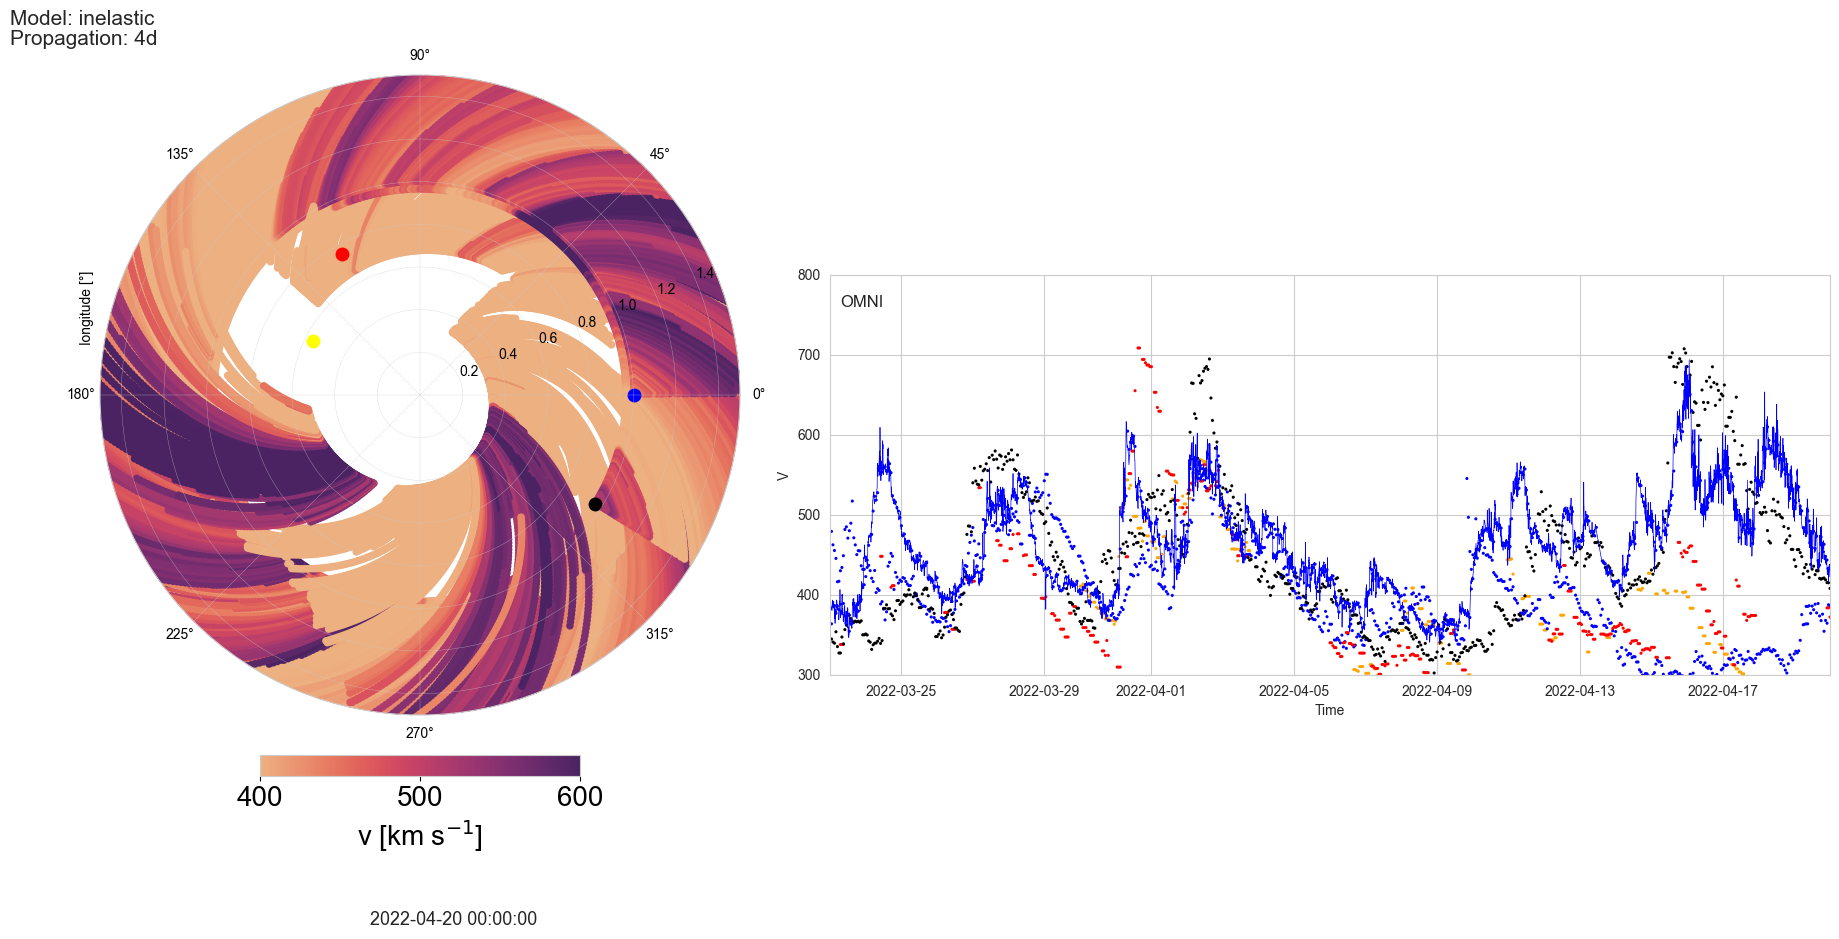

In [3]:
model1.movie(time_window='28d', variable_to_plot='V', cadence='2h', frametrate=30, name='NICEMOVIE', observers=['OMNI'], plot_against_time=True, rlim=1.5)

In [1]:
from P2D import P2D
import seaborn as sns
import matplotlib.pyplot as plt
# Set a single font size for everything
fontsize = 15

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "font.size": fontsize,          # Base font size for everything
        "axes.titlesize": fontsize,     # Axes title
        "axes.labelsize": fontsize,     # Axes labels
        "xtick.labelsize": fontsize,    # X ticks
        "ytick.labelsize": fontsize/1.5,    # Y ticks
        "legend.fontsize": fontsize,    # Legend text
        "figure.titlesize": fontsize,   # Figure title
        "figure.dpi": 100              # Figure quality
    }
)

#timerange=['2023-1-1', '2023-12-20']
timerange=['2022-01-1', '2023-12-20']
#timerange=['2023-11-1', '2023-12-20']

model1 = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'SolO', 'PSP']
                , timerange=timerange
                , propagation_time='5d'
                , model_type='inelastic'
                , degree_resolution=0.5, smooth = '1h', seperate_models=False, only_lowest_MAE=False)#, coordinate_system='other')


# model2 = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'SolO', 'PSP']
#                 , timerange=timerange
#                 , propagation_time='5d'
#                 , model_type='ballistic'
#                 , degree_resolution=0.5, smooth = '1h', seperate_models=False, only_lowest_MAE=True)#, coordinate_system='other')


# Create polar figure
# fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"projection": "polar"})

# Plot your model
#model.plot(rlim=1.8, fighandle=fig, axhandle=ax)



propagating spacecraft data:   0%|          | 0/4 [00:00<?, ?it/s]

OMNI:   0%|          | 0/17233 [00:00<?, ?it/s]

STEREO-A:   0%|          | 0/17233 [00:00<?, ?it/s]

SolO:   0%|          | 0/17233 [00:00<?, ?it/s]

PSP:   0%|          | 0/17232 [00:00<?, ?it/s]

FIRST CUTTING OUT TIMESERIES FROM ['OMNI'] PERSPECTIVE
OMNI


  0%|          | 0/17233 [00:00<?, ?it/s]

COMBINING INTO ONE MODEL


  0%|          | 0/16429 [00:00<?, ?it/s]

Animating:   0%|          | 0/4309 [00:00<?, ?it/s]

2022-03-30 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-30 04:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-30 08:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-30 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-31 04:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-31 08:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-03-31 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-04-29 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-04-29 20:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-04-30 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-04-30 04:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-04-30 08:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-04-30 12:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-04-30 16:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-04-30 20:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-05-01 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-05-01 04:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-10-01 00:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 00:00:00 NO DATA

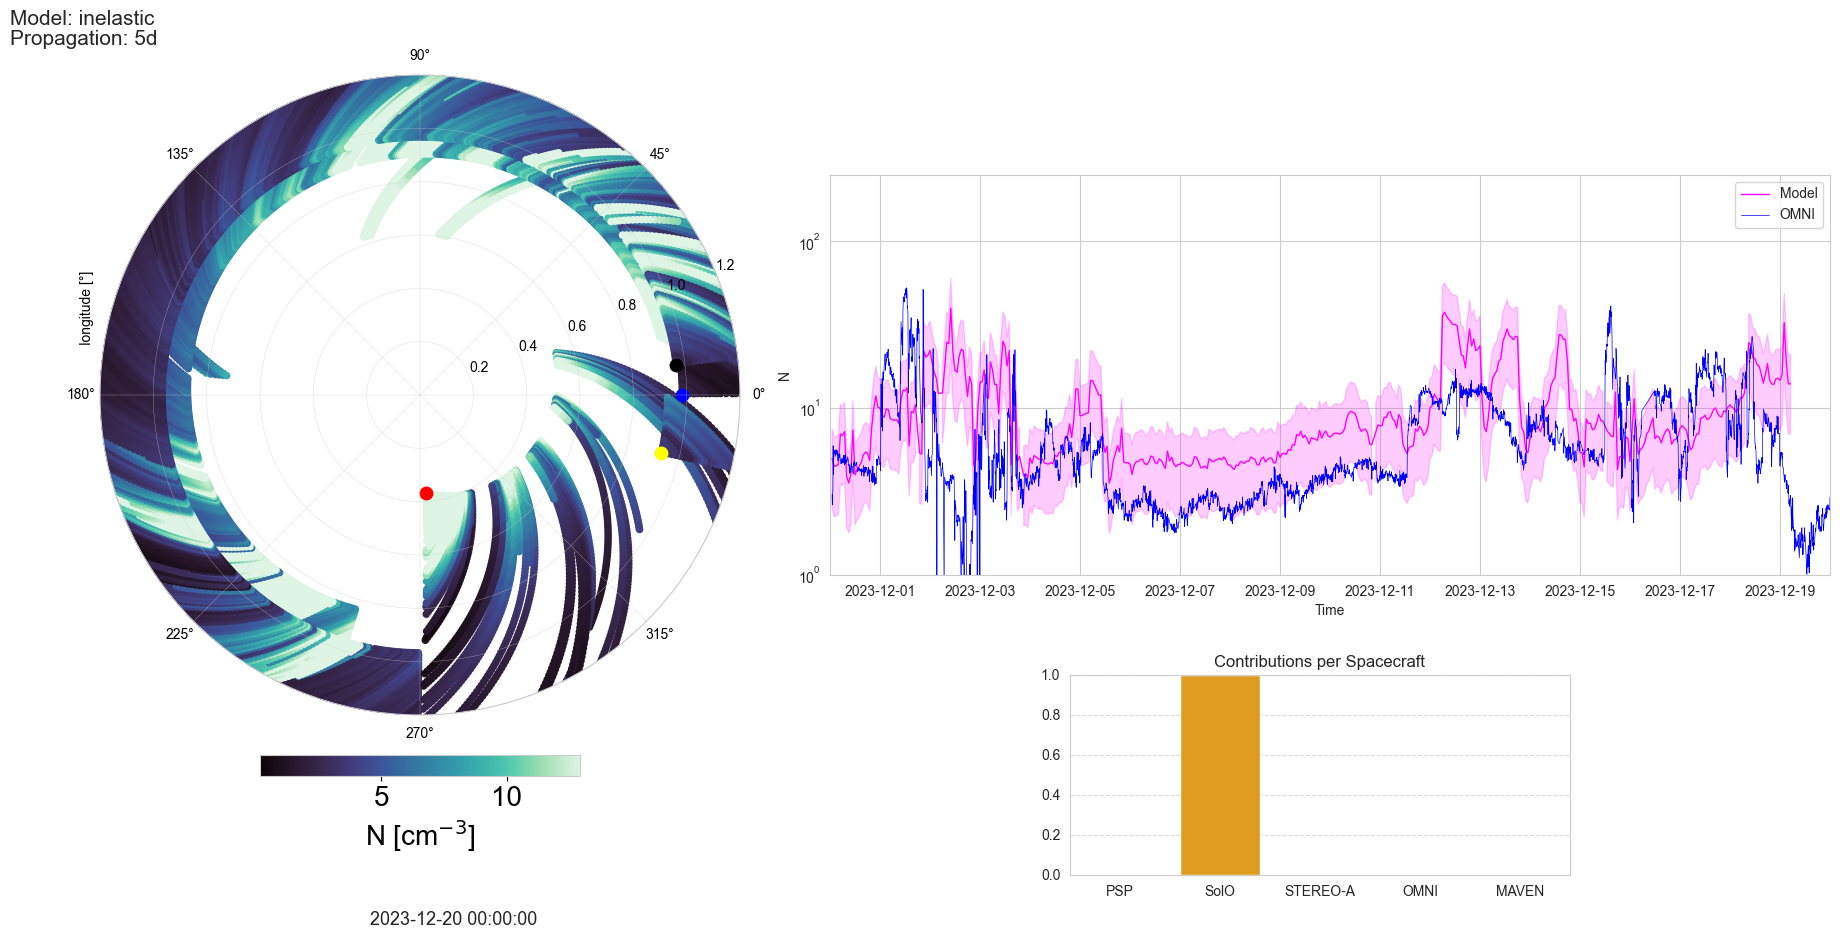

In [2]:
model1.movie(time_window='20d', variable_to_plot='N', cadence='4h', frametrate=30, name='DENS_SUPERLON', observers=['OMNI'], plot_against_time=True)


In [2]:
import pandas as pd

model.observe_from(observer='OMNI', time_window='108d')
time_series:pd.DataFrame = model.list_of_timeseries_cutouts[0]
time_series.to_parquet('model_cutouts/model_results_omni_2h_smoothed_inelastic_100dwindow_part5.parquet')

  0%|          | 0/8017 [00:00<?, ?it/s]

In [ ]:
from P2D import P2D, dataloader

timerange=['2008-01-01', '2008-01-28']

model = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'STEREO-B']
                , timerange=timerange
                , propagation_time='4d'
                , model_type='inelastic'
                , degree_resolution=0.5
                , COR = 0
                , smooth = '1d'
                , lead_time='4d')

model.plot(rlim=3, variable_to_plot='V')



propagating spacecraft data:   0%|          | 0/3 [00:00<?, ?it/s]

OMNI:   0%|          | 0/6073 [00:00<?, ?it/s]

STEREO-A:   0%|          | 0/6073 [00:00<?, ?it/s]

STEREO-B:   0%|          | 0/6073 [00:00<?, ?it/s]

FIRST CUTTING OUT TIMESERIES FROM OMNI PERSPECTIVE
OMNI
OBSERVING FROM OMNI


  0%|          | 0/6073 [00:00<?, ?it/s]

COMBINING INTO ONE MODEL


  0%|          | 0/5461 [00:00<?, ?it/s]

Animating:   0%|          | 0/2026 [00:00<?, ?it/s]

NO CARR_LON DATA FOR THIS TIMERANGE
mp4 file written to P2D_LEAD_TIME_OVERNIGHT_prop_4d_window_28d_60729_sc.mp4


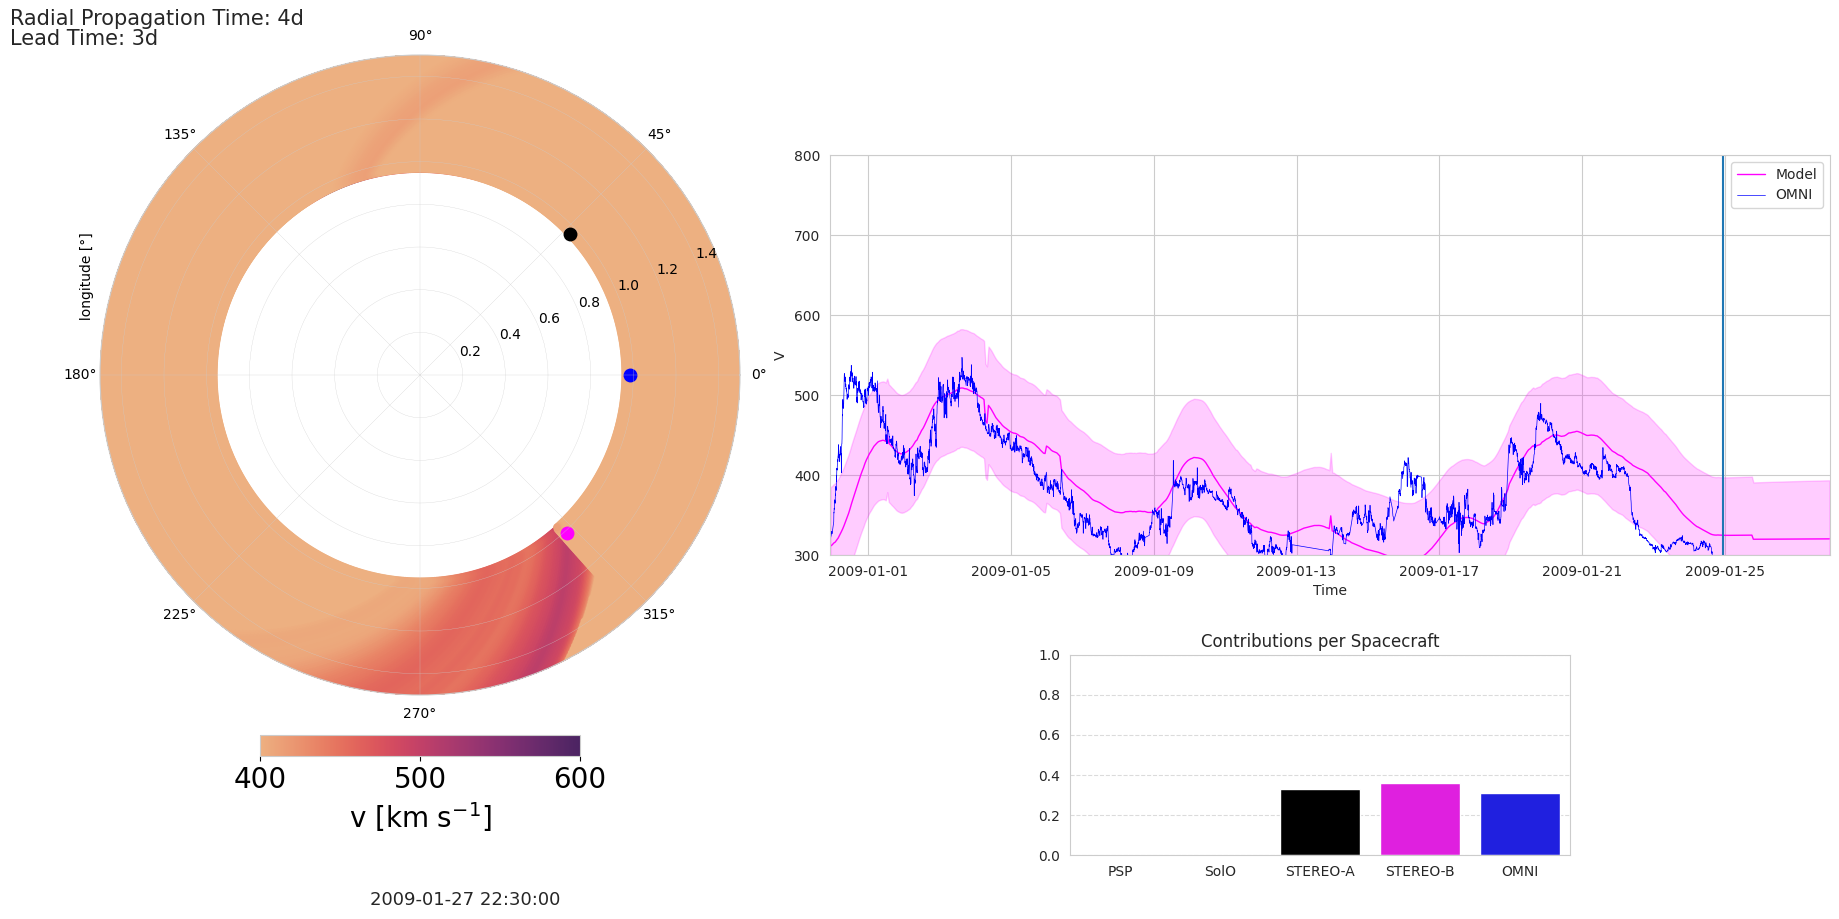

In [2]:
from P2D import P2D, dataloader

timerange=['2008-05-20', '2009-01-28']
#timerange=['2022-2-1', '2022-04-20']

model = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'STEREO-B']
#model = P2D.P2D(input_data=['OMNI', 'STEREO-A', 'SolO', 'PSP']
                , timerange=timerange
                , propagation_time='4d'
                , model_type='inelastic'
                , degree_resolution=0.5
                , COR = 0
                , smooth = '1d'
                , lead_time='3d')


model.movie(time_window='28d', cadence='3h', observers='OMNI', plot_against_time=True, rlim=1.5, name='LEAD_TIME_OVERNIGHT')

In [15]:
import pandas as pd
mask = model.model['Spacecraft_ID'] == 5
model.model.index = model.model.index.where(
    ~mask,
    model.model.index - pd.Timedelta('4.5h')
)
model.model.loc[model.model['Spacecraft_ID'] == 5].index

DatetimeIndex(['2008-02-19 19:30:00', '2008-02-19 20:30:00',
               '2008-02-19 21:30:00', '2008-02-19 21:30:00',
               '2008-02-19 22:30:00', '2008-02-19 22:30:00',
               '2008-02-19 22:30:00', '2008-02-19 23:30:00',
               '2008-02-19 23:30:00', '2008-02-19 23:30:00',
               ...
               '2008-05-27 20:30:00', '2008-05-27 20:30:00',
               '2008-05-27 20:30:00', '2008-05-27 20:30:00',
               '2008-05-27 20:30:00', '2008-05-27 20:30:00',
               '2008-05-27 20:30:00', '2008-05-27 20:30:00',
               '2008-05-27 20:30:00', '2008-05-27 20:30:00'],
              dtype='datetime64[ns]', name='Time', length=221328, freq=None)

In [6]:
model.model

,N,V,CARR_LON_RAD,Index,Sim_step,LAT,INERT_LON,CARR_LON,T,Beta,...,P_B,POL,S_P,Spacecraft_ID,Start_time_of_parcel,Start_R_of_parcel,R,i,V_R,V_N
Time,,,,,,,,,,,,,,,,,,,,,
2008-02-20 00:00:00,3.332500,579.200012,0.394194,0.0,0.0,-6.999121,74.742712,22.58567,142637.250000,3.692500,...,3.502226,-1.000000,5.415092,6.0,2008-02-20 00:00:00,0.988587,0.988587,0.0,NaN,NaN
2008-02-20 01:00:00,3.240480,579.200012,0.384594,0.0,1.0,-6.999121,74.742712,22.58567,142637.250000,3.692500,...,3.502226,-1.000000,5.415092,6.0,2008-02-20 00:00:00,0.988587,1.002525,0.0,NaN,NaN
2008-02-20 02:00:00,3.268750,579.200012,0.383660,1.0,1.0,-6.999886,74.765980,21.98209,141826.875000,2.875000,...,4.958109,-1.000000,5.422413,6.0,2008-02-20 01:00:00,0.988592,0.988592,1.0,NaN,NaN
2008-02-20 02:00:00,3.152220,579.200012,0.374994,0.0,2.0,-6.999121,74.742712,22.58567,142637.250000,3.692500,...,3.502226,-1.000000,5.415092,6.0,2008-02-20 00:00:00,0.988587,1.016463,0.0,NaN,NaN
2008-02-20 03:00:00,3.178491,579.200012,0.374060,1.0,2.0,-6.999886,74.765980,21.98209,141826.875000,2.875000,...,4.958109,-1.000000,5.422413,6.0,2008-02-20 01:00:00,0.988592,1.002530,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008-05-28 01:00:00,13.697139,372.395833,2.517599,2348.0,5.0,-4.345426,145.930977,146.44793,76073.958333,8.406375,...,30.275097,-0.041667,1.160248,5.0,2008-05-27 20:00:00,1.047279,1.028968,2348.0,370.115217,-11.850000
2008-05-28 01:00:00,14.186148,378.072917,2.517548,2349.0,4.0,-4.341513,145.969088,145.894997,80754.375000,7.171367,...,32.141884,0.041667,1.241287,5.0,2008-05-27 21:00:00,1.047307,1.020872,2349.0,375.970652,-12.685870
2008-05-28 01:00:00,14.711269,384.041667,2.517498,2350.0,3.0,-4.337598,146.007197,145.342062,85390.416667,6.363555,...,33.746836,0.125000,1.315512,5.0,2008-05-27 22:00:00,1.047336,1.012529,2350.0,382.178261,-12.978261


In [6]:
model.model.loc[model.model['Spacecraft_ID'] == 9, 'R']*=0.95
model.model.loc[model.model['Spacecraft_ID'] == 9, 'R']

Series([], Name: R, dtype: float64)

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
#%matplotlib widget

#fig, ax = plt.subplots(figsize=(12, 6))

model.observe_from(observer='OMNI', time_window='108d')
time_series:pd.DataFrame = model.list_of_timeseries_cutouts[0]
time_series.to_parquet('model_results_omni_2h_allenrot_smoothed_inelastic_100dwindow_part4.parquet')
#time_series['Persistence_time'] = (time_series.index - time_series['Time']).dt.total_seconds()/3600/24
#time_series = time_series[time_series['Persistence_time']<27]
#time_series['Total_time_difference'] = (time_series['Encounter_time'] - time_series['Start_time_of_parcel']).dt.total_seconds()/3600/24
#time_series = time_series.copy().sort_values(by='Total_time_difference', ascending=True)
# deduped = time_series[~time_series.duplicated(subset='Time',
#                          keep='first'
#                     )].copy()
#model.plot_timeseries(time_series, plot_against_time=True, axhandle=ax, fighandle=fig)#, vline='MAVEN')
#plt.tight_layout()
#ax.set_ylim(200,900)

  0%|          | 0/9433 [00:00<?, ?it/s]

In [ ]:
model.observe_from('OMNI')


FIRST CUTTING OUT TIMESERIES FROM OMNI PERSPECTIVE
OMNI


  0%|          | 0/5809 [00:00<?, ?it/s]

COMBINING INTO ONE MODEL


  0%|          | 0/5743 [00:00<?, ?it/s]

Animating:   0%|          | 0/1937 [00:00<?, ?it/s]

2022-09-30 21:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-09-30 21:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 00:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 00:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 03:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 03:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-10-01 03:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 06:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 06:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-10-01 06:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 09:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 09:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-10-01 09:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 12:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-01 12:00:00 NO DATA, DOWNLOADING OMNI POSITION
2022-10-31 00:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-10-31 03:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-10-31 06:00:00 NO DATA, DOWNLOADING PSP POSITION
2022-10-31 09:00

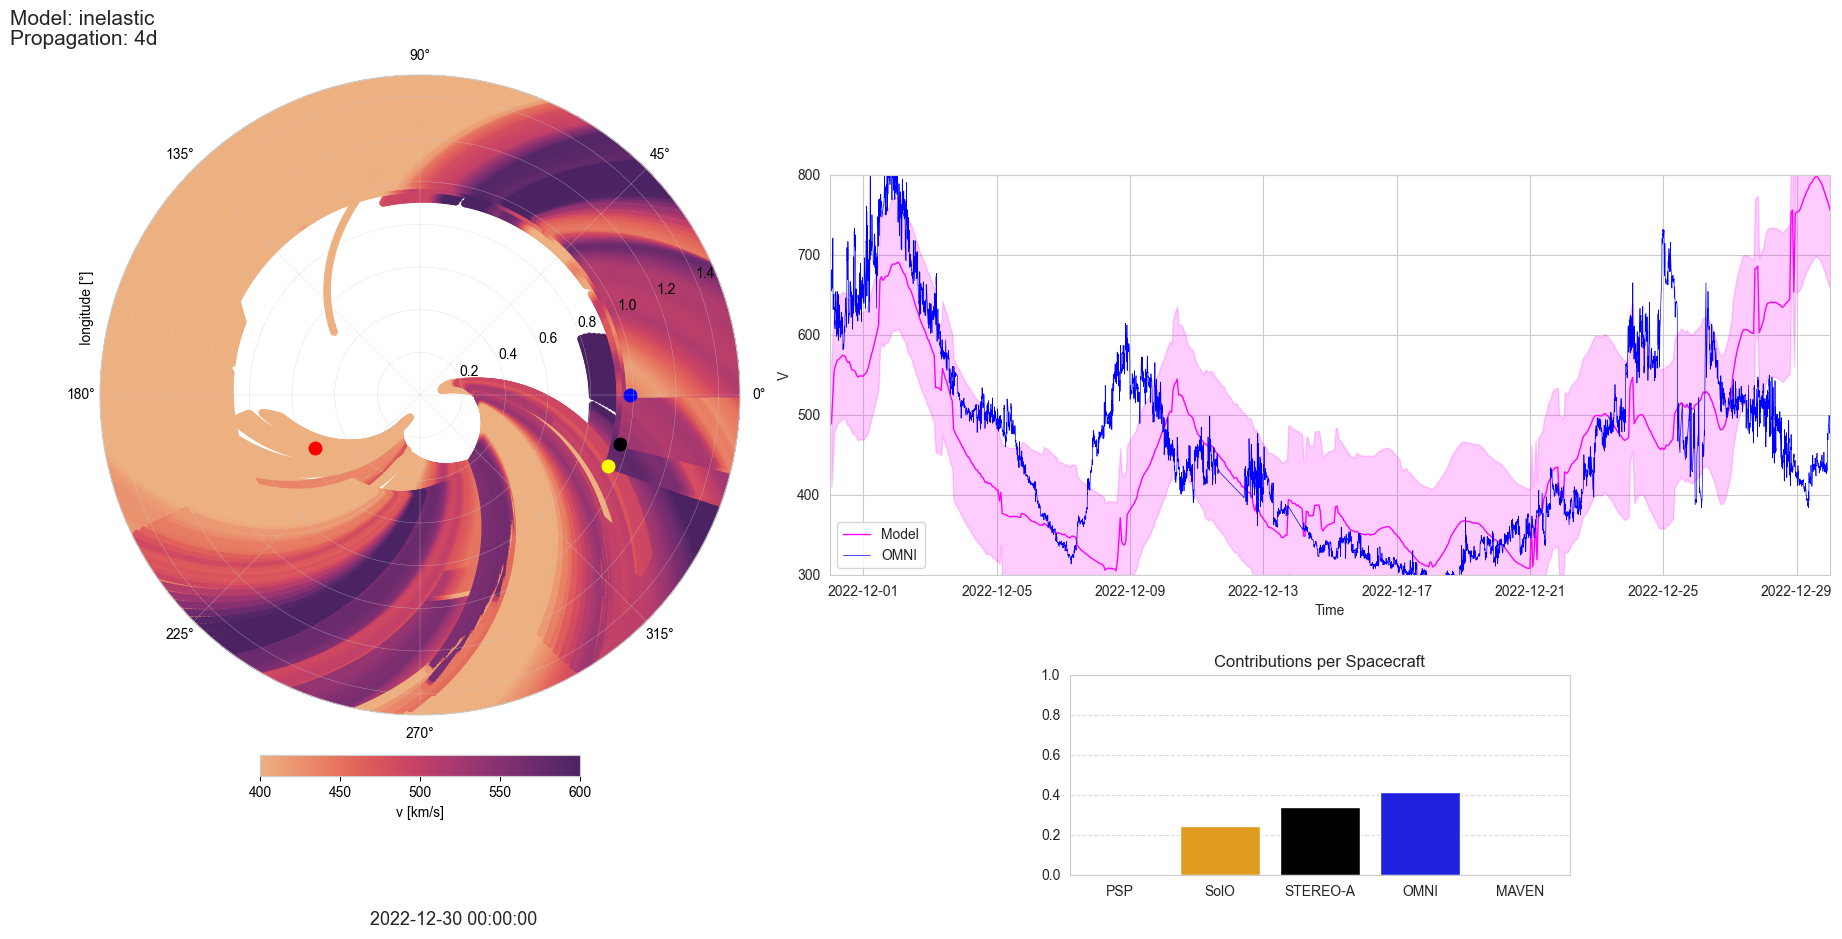

In [2]:
model.movie(time_window='30d', cadence='3h', observers='OMNI', plot_against_time=True, rlim=1.5)

[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2014-03.parquet
[Warning] Skipping 2014-03: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2014-04.parquet
[Warning] Skipping 2014-04: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2014-05.parquet
[Warning] Skipping 2014-05: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2014-06.parquet
[Warning] Skipping 2014-06: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2014-07.parquet
[Warning] Skipping 2014-07: GitHub file not available (404)
[Info] Attempting download from htt

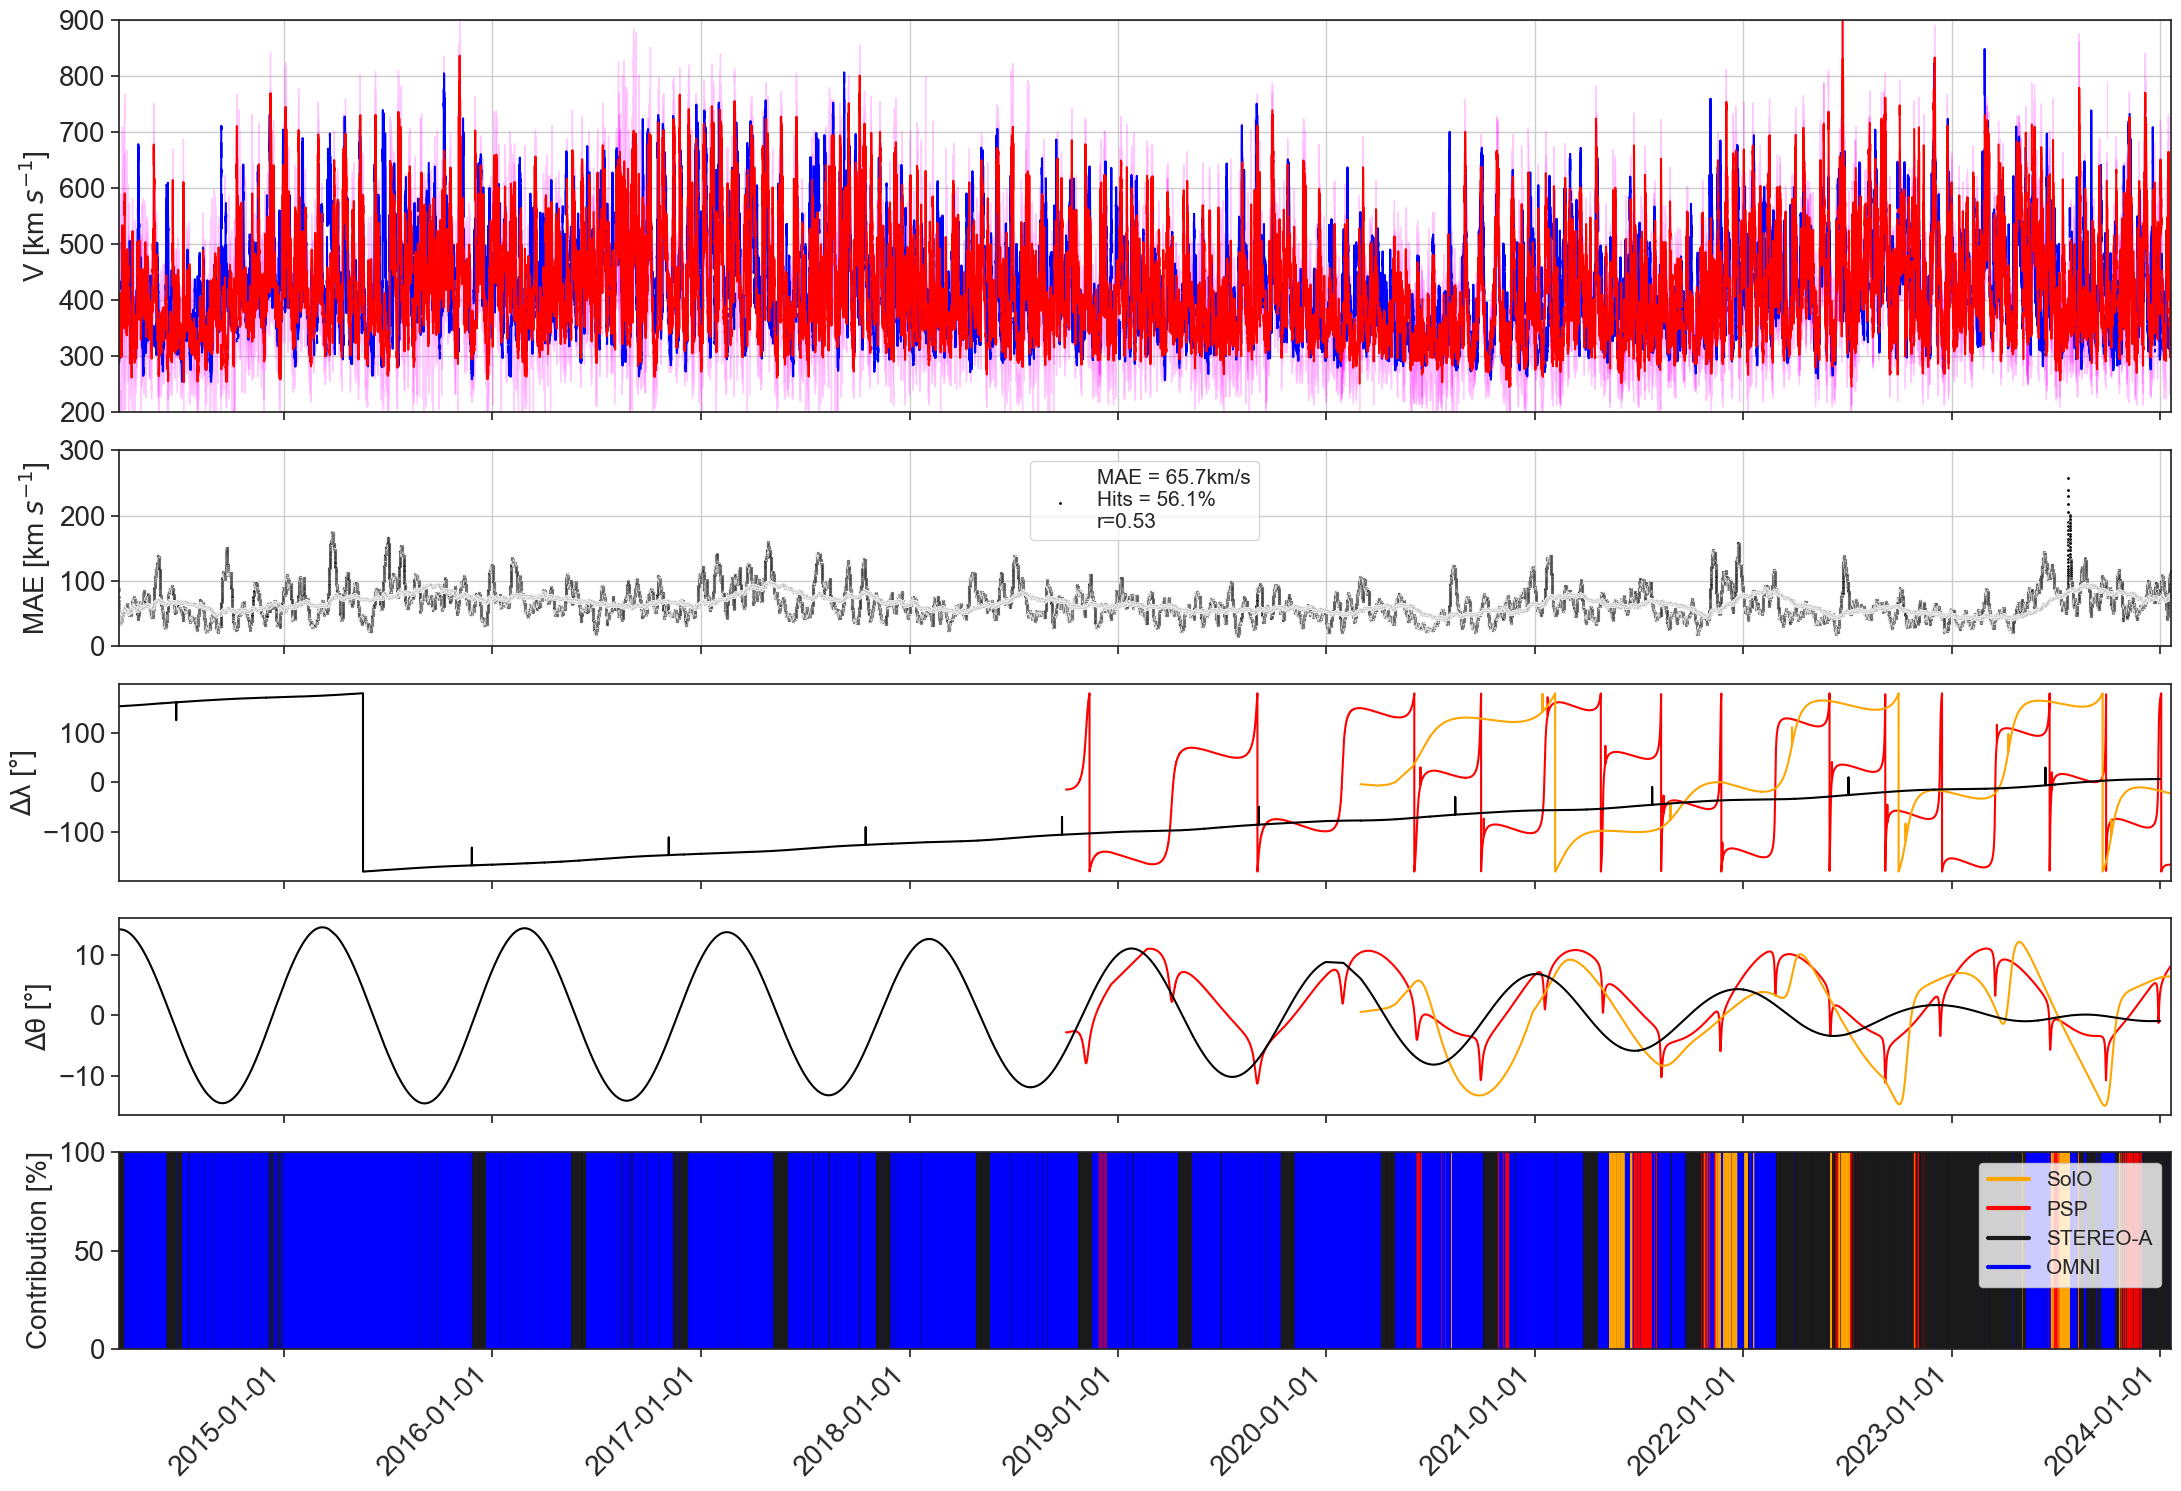

In [1]:


# ONLY LOWEST ERROR


import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import seaborn as sns
from P2D import dataloader
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 20,    # Axis label size
        "xtick.labelsize": 20,   # X-axis tick label size
        "ytick.labelsize": 20,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Paper -> 1000
        "legend.fontsize": 15 # Size of legend
    }
)

#time_series = model2.combined_model
#time_series = pd.read_parquet('least_error_model.parquet')
time_series = pd.read_parquet('single_model_superlong.parquet')

#timeframe = ['2023-10-15', '2023-11-15']
timeframe = None

if timeframe is not None:
    time_series = time_series[timeframe[0]:timeframe[1]]
#time_series = pd.read_parquet('model_results_omni_1dsmoothed_inelastic_100dwindow.parquet')
#time_series['Persistence_time'] = (time_series.index - time_series['Time']).dt.total_seconds()/3600/24
#time_series = time_series[time_series['Persistence_time']<27]
#time_series = time_series[time_series['Spacecraft_ID']!=6]

start_time = time_series.index.min().strftime('%Y-%m-%d-%H:%M')
end_time = time_series.index.max().strftime('%Y-%m-%d-%H:%M')

# Load spacecraft data
spacecraft_data = dataloader.load(spacecraft='OMNI', timerange=[start_time, end_time], cadence='1h')
spacecraft_data = spacecraft_data[~spacecraft_data.index.duplicated(keep='first')]

psp_data = dataloader.load(spacecraft='PSP', timerange=[start_time, end_time], cadence='1h')
solo_data = dataloader.load(spacecraft='SolO', timerange=[start_time, end_time], cadence='1h')
stereo_data = dataloader.load(spacecraft='STEREO-A', timerange=[start_time, end_time], cadence='1h')


carr_lons = pd.DataFrame()
carr_lons['PSP'] = psp_data['INERT_LON']-spacecraft_data['INERT_LON']
carr_lons['SolO'] = solo_data['INERT_LON']-spacecraft_data['INERT_LON']
carr_lons['STEREO-A'] = stereo_data['INERT_LON']-spacecraft_data['INERT_LON']

carr_lons = ((carr_lons + 180) % 360) - 180

lats  = pd.DataFrame()
lats['PSP'] = psp_data['LAT']-spacecraft_data['LAT']
lats['SolO'] = solo_data['LAT']-spacecraft_data['LAT']
lats['STEREO-A'] = stereo_data['LAT']-spacecraft_data['LAT']

#time_series['Total_time_difference'] = (time_series['Encounter_time'] - time_series['Start_time_of_parcel']).dt.total_seconds()/3600/24
#time_series = time_series.copy().sort_values(by='Total_time_difference', ascending=True)
# deduped = time_series[~time_series.duplicated(subset='Time',
#                          keep='first'
#                     )].copy()


remove_cmes=False
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = time_series['Observer_SC']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            time_series[time_mask] = np.nan
            
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = spacecraft_data['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            spacecraft_data[time_mask] = np.nan


time_series['ΔV'] = time_series['V'] - time_series.index.map(spacecraft_data['V'])

time_series['V_MAE'] = abs(time_series['V'] - time_series.index.map(spacecraft_data['V']))

time_series['HITS'] = abs(time_series['V'] - time_series.index.map(spacecraft_data['V'])) < time_series['V_ERROR']

x = time_series['V'].sort_index()
y = x.index.map(spacecraft_data['V'])
mask = ~np.isnan(x) & ~np.isnan(y)
slope, intercept, r_value, p_value, std_err = linregress(x[mask], y[mask])


# Set up figure
fig, ax = plt.subplots(5,1,figsize=(100, 15), sharex=True, height_ratios=[2,1, 1, 1, 1])
import matplotlib.dates as mdates



# Define custom colors and label mapping
custom_palette = {
    6: 'blue',
    7: 'darkred',
    2: 'orange',
    4: 'black',
    1: 'red',
}
label_dict = {
    6: 'OMNI',
    7: 'MAVEN',
    2: 'SolO',
    4: 'STEREO-A',
    1: 'PSP',
}
# Define what counts as a "gap" (e.g., 3 hours)
max_gap = np.timedelta64(3, 'h')

time = spacecraft_data.index
values = spacecraft_data['V'].copy()

# Insert NaN where time gaps exceed threshold
time_diffs = time.to_series().diff().values
gap_indices = np.where(time_diffs > max_gap)[0]
values.iloc[gap_indices] = np.nan

ax[0].plot(time, values, color='blue', label='OMNI in situ')

ax[0].plot(time_series.index, time_series['V'], color='red', label='Combined Model')

ax[0].fill_between(time_series.index, time_series['V'] - time_series['V_ERROR'], time_series['V'] + time_series['V_ERROR'], color='magenta', alpha=0.2)



MAE = time_series['V_MAE'].mean()
HITS = time_series['HITS'].sum()/len(time_series)*100


time_series['AVERAGE_MAE'] = time_series['V_MAE'].rolling(window='10d').mean()

sns.scatterplot(
    data=time_series, x=time_series.index, y='AVERAGE_MAE', 
    color= 'black', ax=ax[1], s=5, label= f'MAE = {MAE:.1f}km/s\nHits = {HITS:.1f}%\nr={r_value:.2f}'
)

time_series['AVERAGE_MAE'] = time_series['V_MAE'].rolling(window='100d').mean()

sns.scatterplot(
    data=time_series, x=time_series.index, y='AVERAGE_MAE', 
    color= 'grey', ax=ax[1], s=5
)

#ax[1].plot(time_series.index, time_series['V_ERROR'], color='red', label='ERROR')
#ax[1].legend(loc='upper right')


# Beautify time axis
ax[0].xaxis.set_major_locator(mdates.AutoDateLocator())  # or WeekLocator(), AutoDateLocator()
ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # or '%b %Y' for abbreviated months
plt.setp(ax[4].get_xticklabels(), rotation=45, ha='right')  # Rotate for readability



colors = {
    'SolO': 'orange',
    'PSP': 'red',
    'STEREO-A': 'k',
    'OMNI': 'blue'
}

sns.lineplot(carr_lons['PSP'], color='red', ax=ax[2])
sns.lineplot(carr_lons['SolO'], color='orange', ax=ax[2])
sns.lineplot(carr_lons['STEREO-A'], color='black', ax=ax[2])

sns.lineplot(lats['PSP'], color='red', ax=ax[3])
sns.lineplot(lats['SolO'], color='orange', ax=ax[3])
sns.lineplot(lats['STEREO-A'], color='black', ax=ax[3])


# Define colors for each spacecraft
colors = {
    'Contribution from SolO': 'orange',
    'Contribution from PSP': 'red',
    'Contribution from STEREO-A': 'k',
    'Contribution from OMNI': 'blue'
}

# Find which spacecraft contributes (value == 1)
active = time_series[['Contribution from SolO', 'Contribution from PSP',
                      'Contribution from STEREO-A', 'Contribution from OMNI']].idxmax(axis=1)

# Plot vertical lines at each time, color-coded
for i, (t, col) in enumerate(zip(time_series.index, active)):
    ax[4].vlines(t, 0, 100, color=colors[col], linewidth=1)

# Axis and legend setup
ax[4].set_ylabel('Contribution [%]')
ax[4].set_ylim(0, 100)

ax[4].legend(handles=[
    plt.Line2D([0], [0], color='orange', linewidth=3, label='SolO'),
    plt.Line2D([0], [0], color='red', linewidth=3, label='PSP'),
    plt.Line2D([0], [0], color='k', linewidth=3, label='STEREO-A'),
    plt.Line2D([0], [0], color='blue', linewidth=3, label='OMNI'),
])
#ax[4].legend()

ax[0].set_ylabel(r'V [km $s^{-1}$]')
ax[0].set_xlim(time_series.index.min(), time_series.index.max())

ax[0].set_ylim(200,900)
ax[1].set_ylim(0,300)

ax[1].set_ylabel(r'MAE [km $s^{-1}$]')
#ax[4].set_ylabel('AE [km/s]')
# Final touches
ax[0].grid()
ax[1].grid()
ax[1].set_xlabel('')

ax[3].set_ylabel('Δθ [°]')
ax[2].set_ylabel('Δλ [°]')

ax[4].grid()
ax[4].set_xlabel('')
plt.tight_layout()
plt.show()


In [ ]:


# PLOT DATA AVAILABILITY


import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import seaborn as sns
from P2D import dataloader
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 20,    # Axis label size
        "xtick.labelsize": 20,   # X-axis tick label size
        "ytick.labelsize": 20,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Paper -> 1000
        "legend.fontsize": 15 # Size of legend
    }
)


start_time = '2008-01-01'
end_time = '2026-01-01'

# Load spacecraft data
spacecraft_data = dataloader.load(spacecraft='OMNI', timerange=[start_time, end_time], cadence='1h')
spacecraft_data = spacecraft_data[~spacecraft_data.index.duplicated(keep='first')]

omni_data = dataloader.load(spacecraft='OMNI', timerange=[start_time, end_time], cadence='1h')
omni_data.dropna(subset='V', inplace=True)
psp_data = dataloader.load(spacecraft='PSP', timerange=[start_time, end_time], cadence='1h')
psp_data.dropna(subset='V', inplace=True)
# solo_data = dataloader.load(spacecraft='SolO', timerange=[start_time, end_time], cadence='1h')
# stereo_data = dataloader.load(spacecraft='STEREO-A', timerange=[start_time, end_time], cadence='1h')

fig, ax = plt.subplots(5,1,figsize=(18, 14), sharex=True, height_ratios=[1, 1, 1, 1, 1])

# Plot vertical lines at each time, color-coded
for t in omni_data.index:
    ax[0].vlines(t, 0, 100, color='blue', linewidth=1)
ax[0].set_ylabel('OMNI')
ax[0].set_xlim(omni_data.index.min(), omni_data.index.max())

for t in psp_data.index:
    ax[3].vlines(t, 0, 100, color='blue', linewidth=1)
ax[3].set_ylabel('PSP')
ax[3].set_xlim(omni_data.index.min(), omni_data.index.max())


plt.tight_layout()
plt.show()


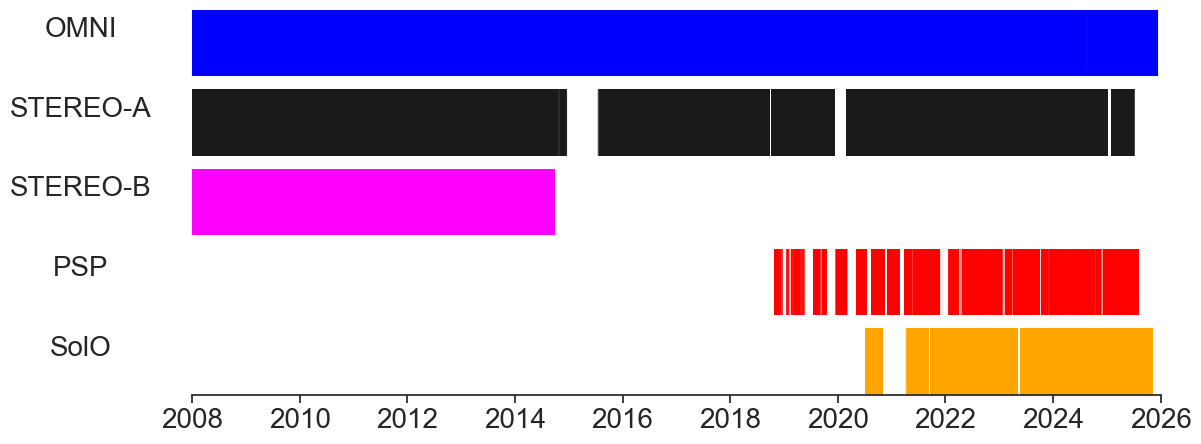

In [33]:
# PLOT DATA AVAILABILITY (more efficient)

import matplotlib.pyplot as plt
import seaborn as sns
from P2D import dataloader
import pandas as pd

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 20,
        "xtick.labelsize": 20,
        "ytick.labelsize": 20,
        "font.size": 13,
        "figure.dpi": 100,
        "legend.fontsize": 15,
    }
)

start_time = "2008-01-01"
end_time   = "2026-01-01"

# -------------------------------------------------
# Load once only 
# -------------------------------------------------
# datasets = {
#     "OMNI": dataloader.load(
#         spacecraft="OMNI",
#         timerange=[start_time, end_time],
#         cadence="1h"
#     ),
#     "PSP": dataloader.load(
#         spacecraft="PSP",
#         timerange=[start_time, end_time],
#         cadence="1h"
#     ),
#     "SolO": dataloader.load(
#         spacecraft="SolO",
#         timerange=[start_time, end_time],
#         cadence="1h"
#     ),
#     "STEREO-A": dataloader.load(
#         spacecraft="STEREO-A",
#         timerange=[start_time, end_time],
#         cadence="1h"
#     ),
#     "STEREO-B": dataloader.load(
#         spacecraft="STEREO-B",
#         timerange=[start_time, end_time],
#         cadence="1h"
#     ),
# }

colors = {
    'SolO': 'orange',
    'PSP': 'red',
    'STEREO-A': 'k',
    'STEREO-B': 'magenta',
    'OMNI': 'blue'
}

# Clean data
for name, df in datasets.items():
    df = df[~df.index.duplicated(keep="first")]
    df = df.dropna(subset=["V"])
    df = df.dropna(subset=["N"])
    datasets[name] = df

# -------------------------------------------------
# Figure
# -------------------------------------------------
fig, ax = plt.subplots(
    5, 1,
    figsize=(12.5, 5),
    #sharex=True,
    height_ratios=[1, 1, 1, 1, 1]
)

# -------------------------------------------------
# Faster plotting using eventplot instead of many vlines
# -------------------------------------------------
plot_rows = {
    "OMNI": 0,
    "STEREO-A":1,
    "STEREO-B":2,
    "PSP": 3,
    "SolO":4
}

for name, row in plot_rows.items():
    times = datasets[name].index
    color=colors[name]
    ax[row].eventplot(
        times,
        orientation="horizontal",
        colors=color,
        lineoffsets=0.5,
        linelengths=1.0,
        linewidths=0.1
    )
    ax[row].set_ylim(0, 1)
    ax[row].set_ylabel(name, rotation=0, labelpad = 80)
    ax[row].set_yticks([])
    ax[row].spines['top'].set_visible(False)
    ax[row].spines['bottom'].set_visible(False)
    ax[row].spines['left'].set_visible(False)
    ax[row].spines['right'].set_visible(False)

ax[0].set_xticks([])
ax[1].set_xticks([])
ax[2].set_xticks([])
ax[3].set_xticks([])
ax[-1].spines['bottom'].set_visible(True)
# Shared x-limits
xmin = min(df.index.min() for df in datasets.values())
xmax = max(df.index.max() for df in datasets.values())
xmax = pd.to_datetime('2026-01-01')

for a in ax:
    a.set_xlim(xmin, xmax)

#plt.tight_layout()
plt.show()

In [ ]:


#  COMBINED


import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import seaborn as sns
from P2D import dataloader
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 20,    # Axis label size
        "xtick.labelsize": 20,   # X-axis tick label size
        "ytick.labelsize": 20,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Paper -> 1000
        "legend.fontsize": 15 # Size of legend
    }
)

fig, ax = plt.subplots(5,1,figsize=(18, 14), sharex=True, height_ratios=[1, 1, 1, 1, 1])

#time_series = model2.combined_model
time_series = pd.read_parquet('combined_model_superlong.parquet')



timeframe = ['2018-01-01', '2022-1-1']
#timeframe = None

if timeframe is not None:
    time_series = time_series[timeframe[0]:timeframe[1]]
#time_series = pd.read_parquet('model_results_omni_1dsmoothed_inelastic_100dwindow.parquet')
#time_series['Persistence_time'] = (time_series.index - time_series['Time']).dt.total_seconds()/3600/24
#time_series = time_series[time_series['Persistence_time']<27]
#time_series = time_series[time_series['Spacecraft_ID']!=6]

start_time = time_series.index.min().strftime('%Y-%m-%d-%H:%M')
start_time_omni = pd.to_datetime(time_series.index.min()) - pd.Timedelta('120d')
start_time_omni=start_time_omni.strftime('%Y-%m-%d-%H:%M')
end_time = time_series.index.max().strftime('%Y-%m-%d-%H:%M')

# Load spacecraft data
spacecraft_data = dataloader.load(spacecraft='OMNI', timerange=[start_time, end_time])#, cadence='1h')
spacecraft_data = spacecraft_data[~spacecraft_data.index.duplicated(keep='first')]


psp_data = dataloader.load(spacecraft='PSP', timerange=[start_time, end_time])#, cadence='1h')
psp_data = psp_data[~psp_data.index.duplicated(keep='first')]
solo_data = dataloader.load(spacecraft='SolO', timerange=[start_time, end_time])#, cadence='1h')
solo_data = solo_data[~solo_data.index.duplicated(keep='first')]
stereo_data = dataloader.load(spacecraft='STEREO-A', timerange=[start_time, end_time])#, cadence='1h')
stereo_data = stereo_data[~stereo_data.index.duplicated(keep='first')]
omni_data = dataloader.load(spacecraft='OMNI', timerange=[start_time_omni, end_time])#, cadence='1h')
omni_data = omni_data.shift(27, pd.Timedelta('1d'))
omni_data = omni_data[~omni_data.index.duplicated(keep='first')]



carr_lons = pd.DataFrame()
carr_lons['PSP'] = -(psp_data['INERT_LON']-spacecraft_data['INERT_LON'])
carr_lons['SolO'] = -(solo_data['INERT_LON']-spacecraft_data['INERT_LON'])
carr_lons['STEREO-A'] = -(stereo_data['INERT_LON']-spacecraft_data['INERT_LON'])
carr_lons['OMNI'] = -(omni_data['INERT_LON']-spacecraft_data['INERT_LON'])


#carr_lons = ((carr_lons + 180) % 360) - 180
carr_lons = ((carr_lons) % 360) * (365 + 27)/365
carr_lons['OMNI']+=360

#carr_lons['OMNI'] = 360 - carr_lons['OMNI'] +360

lats  = pd.DataFrame()
lats['PSP'] = psp_data['LAT']-spacecraft_data['LAT']
lats['SolO'] = solo_data['LAT']-spacecraft_data['LAT']
lats['STEREO-A'] = stereo_data['LAT']-spacecraft_data['LAT']
lats['OMNI'] = omni_data['LAT']-spacecraft_data['LAT']



V_ERRORS = pd.DataFrame()

V_ERRORS['PSP'] = abs(lats['PSP'])*2.4 + np.log(abs(carr_lons['PSP'])*27.27/360)*9.1 + 40.9
V_ERRORS['SolO'] = abs(lats['SolO'])*2.4 + np.log(abs(carr_lons['SolO'])*27.27/360)*9.1 + 40.9
V_ERRORS['STEREO-A'] = abs(lats['STEREO-A'])*2.4 + np.log(abs(carr_lons['STEREO-A'])*27.27/360)*9.1 + 40.9
V_ERRORS['OMNI'] = abs(lats['OMNI'])*2.4 + np.log(abs(carr_lons['OMNI'])*27.27/360)*9.1 + 40.9

V_ERRORS.interpolate(method='linear', time='1h', inplace=True)
V_ERRORS[V_ERRORS.isna()]=10000000

V_CONTRIBUTIONS = pd.DataFrame()

V_ERRORS[V_ERRORS< 40.9] =40.9


V_CONTRIBUTIONS['PSP'] = (1/V_ERRORS['PSP'])/((1/V_ERRORS['PSP'])+(1/V_ERRORS['SolO'])+(1/V_ERRORS['STEREO-A'])+(1/V_ERRORS['OMNI']))
V_CONTRIBUTIONS['SolO'] = (1/V_ERRORS['SolO'])/((1/V_ERRORS['PSP'])+(1/V_ERRORS['SolO'])+(1/V_ERRORS['STEREO-A'])+(1/V_ERRORS['OMNI']))
V_CONTRIBUTIONS['STEREO-A'] = (1/V_ERRORS['STEREO-A'])/((1/V_ERRORS['PSP'])+(1/V_ERRORS['SolO'])+(1/V_ERRORS['STEREO-A'])+(1/V_ERRORS['OMNI']))
V_CONTRIBUTIONS['OMNI'] = (1/V_ERRORS['OMNI'])/((1/V_ERRORS['PSP'])+(1/V_ERRORS['SolO'])+(1/V_ERRORS['STEREO-A'])+(1/V_ERRORS['OMNI']))
V_CONTRIBUTIONS.interpolate(method='linear', time='1h', inplace=True)


V_ERRORS[V_ERRORS>100000]=np.nan
V_ERRORS[V_ERRORS< 40.9] =40.9


V_CONTRIBUTIONS[V_CONTRIBUTIONS.isna()]=0

N_ERRORS = pd.DataFrame()

N_ERRORS['PSP'] = abs(lats['PSP'])*0.03 + np.log(abs(carr_lons['PSP'])*27.27/360)*0.23 + 2
N_ERRORS['SolO'] = abs(lats['SolO'])*0.03 + np.log(abs(carr_lons['SolO'])*27.27/360)*0.23 + 2
N_ERRORS['STEREO-A'] = abs(lats['STEREO-A'])*0.03 + np.log(abs(carr_lons['STEREO-A'])*27.27/360)*0.23 + 2
N_ERRORS['OMNI'] = abs(lats['OMNI'])*0.03 + np.log(abs(carr_lons['OMNI'])*27.27/360)*0.23 + 2

N_ERRORS[N_ERRORS< 2] =2





time_series['V_MAE'] = abs(time_series['V'] - time_series.index.map(spacecraft_data['V']))

time_series['N_MAE'] = abs(time_series['N'] - time_series.index.map(spacecraft_data['N']))


import matplotlib.dates as mdates



# Define custom colors and label mapping
custom_palette = {
    6: 'blue',
    7: 'darkred',
    2: 'orange',
    4: 'black',
    1: 'red',
}
label_dict = {
    6: 'OMNI',
    7: 'MAVEN',
    2: 'SolO',
    4: 'STEREO-A',
    1: 'PSP',
}
# Define what counts as a "gap" (e.g., 3 hours)
max_gap = np.timedelta64(3, 'h')

time = spacecraft_data.index
values = spacecraft_data['V'].copy()

# Insert NaN where time gaps exceed threshold
time_diffs = time.to_series().diff().values
gap_indices = np.where(time_diffs > max_gap)[0]
values.iloc[gap_indices] = np.nan


time_series['AVERAGE_MAE_V'] = time_series['V_MAE'].rolling(window='10d').mean()
time_series['AVERAGE_MAE_N'] = time_series['N_MAE'].rolling(window='10d').mean()



# Beautify time axis
ax[2].xaxis.set_major_locator(mdates.AutoDateLocator())  # or WeekLocator(), AutoDateLocator()
ax[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # or '%b %Y' for abbreviated months
plt.setp(ax[1].get_xticklabels(), rotation=45, ha='right')  # Rotate for readability



colors = {
    'SolO': 'orange',
    'PSP': 'red',
    'STEREO-A': 'k',
    'OMNI': 'blue'
}


sns.lineplot(V_ERRORS['PSP'], color='red', ax=ax[2])
sns.lineplot(V_ERRORS['SolO'], color='orange', ax=ax[2])
sns.lineplot(V_ERRORS['STEREO-A'], color='black', ax=ax[2])
sns.lineplot(V_ERRORS['OMNI'], color='blue', ax=ax[2])

sns.lineplot(N_ERRORS['PSP'], color='red', ax=ax[3])
sns.lineplot(N_ERRORS['SolO'], color='orange', ax=ax[3])
sns.lineplot(N_ERRORS['STEREO-A'], color='black', ax=ax[3])
sns.lineplot(N_ERRORS['OMNI'], color='blue', ax=ax[3])


sns.lineplot(carr_lons['PSP'], color='red', ax=ax[1])
sns.lineplot(carr_lons['SolO'], color='orange', ax=ax[1])
sns.lineplot(carr_lons['STEREO-A'], color='black', ax=ax[1])
sns.lineplot(carr_lons['OMNI'], color='blue', ax=ax[1])

sns.lineplot(lats['PSP'], color='red', ax=ax[0])
sns.lineplot(lats['SolO'], color='orange', ax=ax[0])
sns.lineplot(lats['STEREO-A'], color='black', ax=ax[0])
sns.lineplot(lats['OMNI'], color='blue', ax=ax[0])




# Define colors for each spacecraft
colors = {
    'Contribution from SolO': 'orange',
    'Contribution from PSP': 'red',
    'Contribution from STEREO-A': 'k',
    'Contribution from OMNI': 'blue'
}

# Find which spacecraft contributes (value == 1)
active = time_series[['Contribution from SolO', 'Contribution from PSP',
                      'Contribution from STEREO-A', 'Contribution from OMNI']].idxmax(axis=1)



ax[4].fill_between(x = V_CONTRIBUTIONS.index, 
                   y1 = 0, 
                   y2 = V_CONTRIBUTIONS['OMNI']*100, color = 'blue')

ax[4].fill_between(x = V_CONTRIBUTIONS.index, 
                   y1 = V_CONTRIBUTIONS['OMNI']*100,
                   y2 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100, color = 'black')

ax[4].fill_between(x = V_CONTRIBUTIONS.index, 
                   y1 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100
                   , y2 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100+ V_CONTRIBUTIONS['PSP']*100,color = 'red')

ax[4].fill_between(x = V_CONTRIBUTIONS.index, 
                   y1 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100+ V_CONTRIBUTIONS['PSP']*100
                   , y2 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100+ V_CONTRIBUTIONS['PSP']*100 + V_CONTRIBUTIONS['SolO']*100, color = 'orange')


# Axis and legend setup
ax[4].set_ylabel('Contribution [%]')
ax[4].set_ylim(0, 100)

ax[0].legend(handles=[
    plt.Line2D([2], [2], color='orange', linewidth=3, label='SolO'),
    plt.Line2D([2], [2], color='red', linewidth=3, label='PSP'),
    plt.Line2D([2], [2], color='k', linewidth=3, label='STEREO-A'),
    plt.Line2D([2], [2], color='blue', linewidth=3, label='OMNI'),
    ], loc='upper left')
#ax[1].legend()

ax[2].set_ylabel(r'V [km $s^{-1}$]')
ax[3].set_ylabel(r'N [$cm^{-3}$]')
ax[2].set_xlim(time_series.index.min(), time_series.index.max())

ax[2].set_ylim(200,900)
ax[2].set_ylim(40,110)

ax[2].set_ylabel(r'ΔV [km $s^{-1}$]')
ax[3].set_ylabel(r'ΔN [$cm^{-3}$]')
#ax[1].set_ylabel('AE [km/s]')
# Final touches
ax[2].grid()
ax[2].grid()
ax[2].set_xlabel('')

ax[0].set_ylabel('Δλ [°]')
ax[1].set_ylabel('Δφ [°]')
#ax[1].set_ylim(-10,390)
ax[1].set_yticks((0,180,360))
plt.setp(ax[4].get_xticklabels(), rotation=45, ha='right')
ax[4].grid()
ax[4].set_xlabel('')

labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']
for a, label in zip(ax.flatten(), labels):
    a.text(
        0.95, 0.92, label,
        transform=a.transAxes,
        ha='right', va='top',
        fontsize=24, fontweight='bold'
    )


plt.tight_layout()
plt.show()


[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2018-01.parquet
[Warning] Skipping 2018-01: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2018-02.parquet
[Warning] Skipping 2018-02: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2018-03.parquet
[Warning] Skipping 2018-03: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2018-04.parquet
[Warning] Skipping 2018-04: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2018-05.parquet
[Warning] Skipping 2018-05: GitHub file not available (404)
[Info] Attempting download from htt

[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2008-01.parquet
[Warning] Skipping 2008-01: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2008-02.parquet
[Warning] Skipping 2008-02: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2008-03.parquet
[Warning] Skipping 2008-03: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2008-04.parquet
[Warning] Skipping 2008-04: GitHub file not available (404)
[Info] Attempting download from https://raw.githubusercontent.com/danielmilosic/DRaD/master/reduced_data/psp/psp_data2008-05.parquet
[Warning] Skipping 2008-05: GitHub file not available (404)
[Info] Attempting download from htt

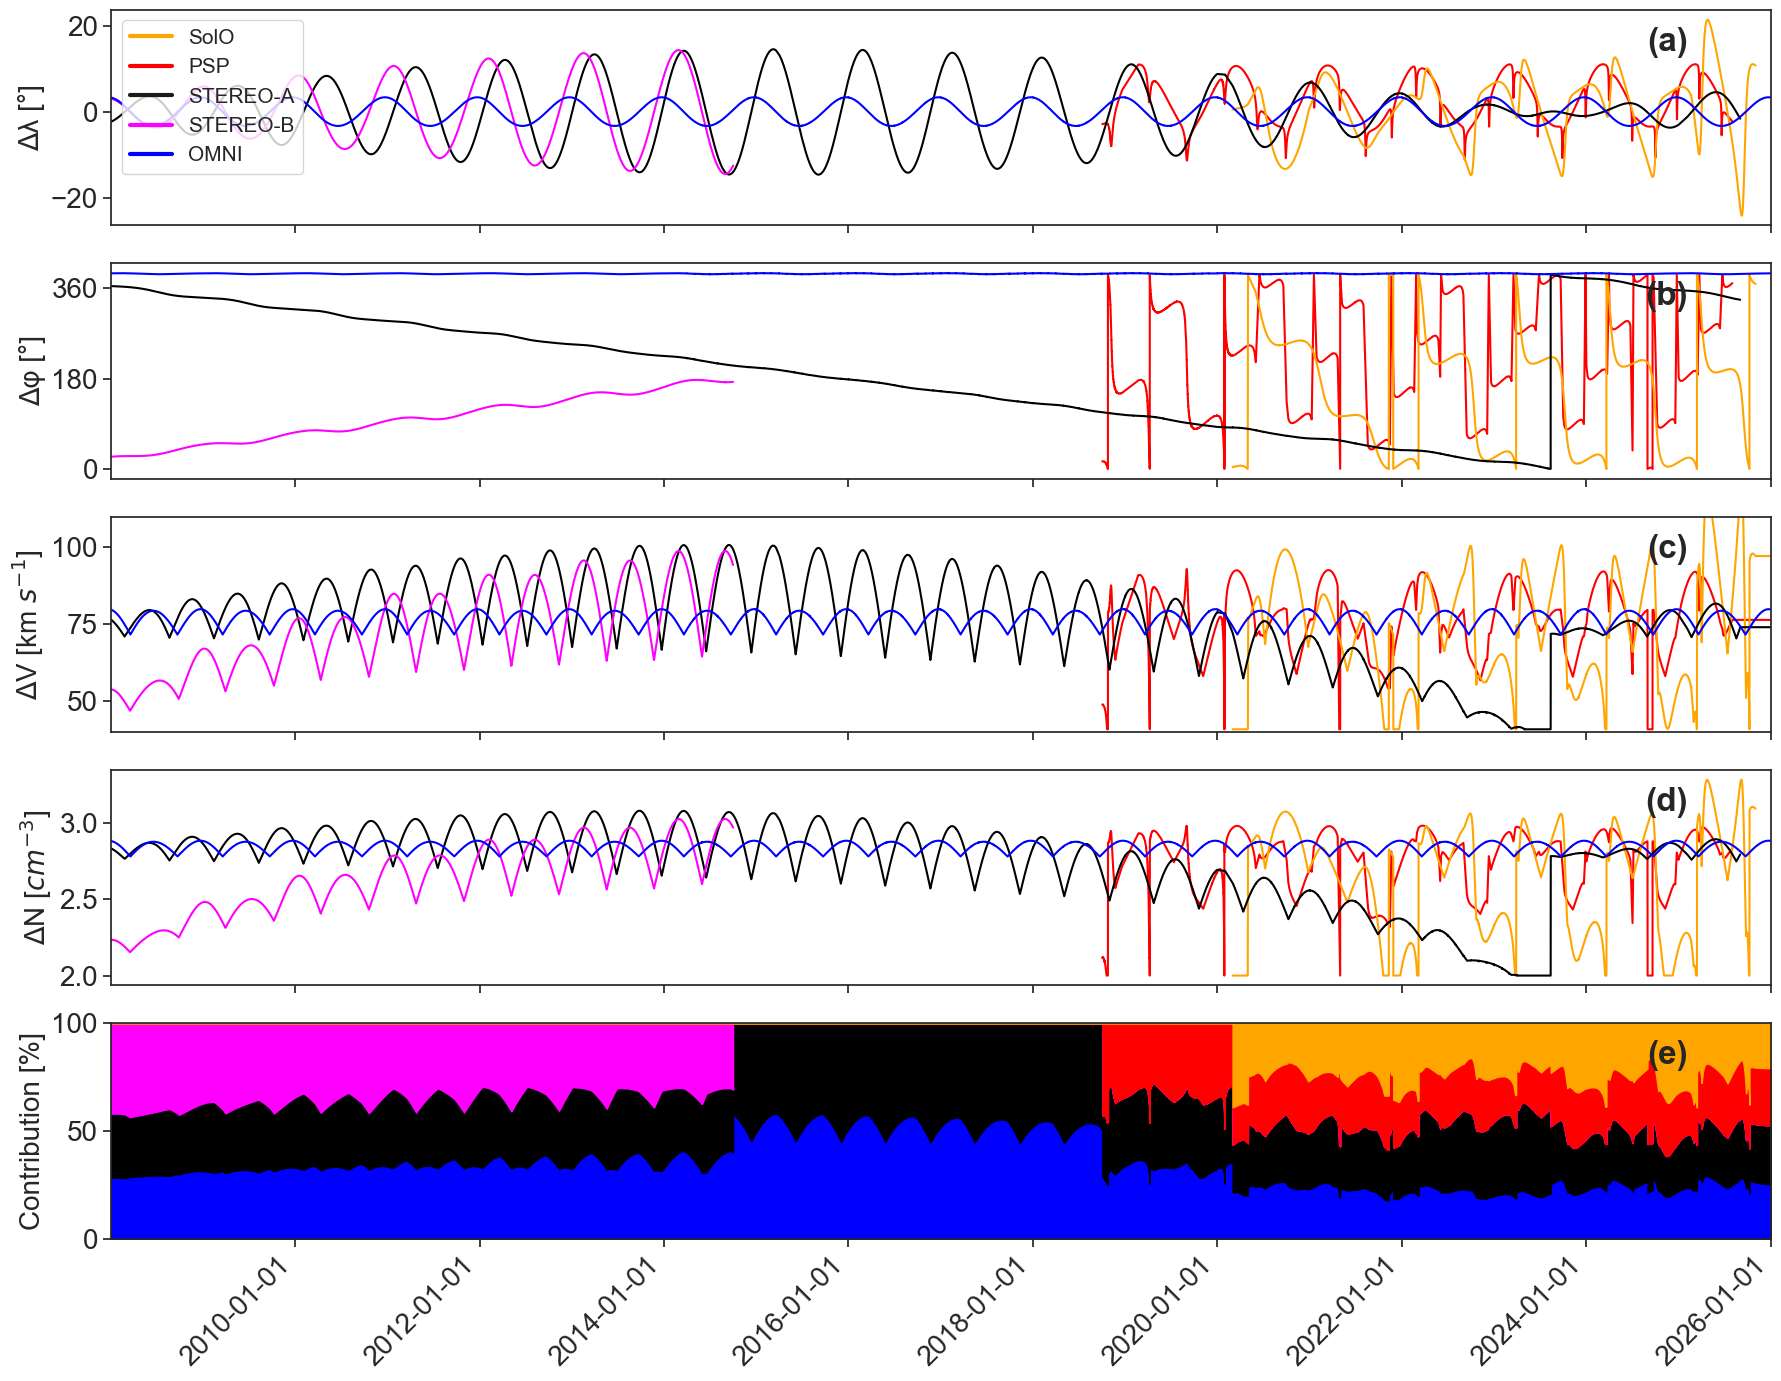

In [1]:


#  COMBINED


import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import seaborn as sns
from P2D import dataloader
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 20,    # Axis label size
        "xtick.labelsize": 20,   # X-axis tick label size
        "ytick.labelsize": 20,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Paper -> 1000
        "legend.fontsize": 15 # Size of legend
    }
)

fig, ax = plt.subplots(5,1,figsize=(18, 14), sharex=True, height_ratios=[1, 1, 1, 1, 1])

#time_series = model2.combined_model
time_series_1 = pd.read_parquet('combined_model_superlong_2008_2015_1d_smooth.parquet')
time_series_2 = pd.read_parquet('single_model_superlong.parquet')
time_series_3 = pd.read_parquet('combined_model_superlong_2023_2026_1d_smooth.parquet')

time_series_2 = time_series_2.loc[time_series_1.index[-1]:]
time_series_3 = time_series_3.loc[time_series_2.index[-1]:]
time_series = pd.concat([time_series_1, time_series_2, time_series_3]).drop_duplicates(keep='first')

timeframe = ['2008-01-01', '2012-1-1']
timeframe = None

if timeframe is not None:
    time_series = time_series[timeframe[0]:timeframe[1]]
#time_series = pd.read_parquet('model_results_omni_1dsmoothed_inelastic_100dwindow.parquet')
#time_series['Persistence_time'] = (time_series.index - time_series['Time']).dt.total_seconds()/3600/24
#time_series = time_series[time_series['Persistence_time']<27]
#time_series = time_series[time_series['Spacecraft_ID']!=6]

start_time = time_series.index.min().strftime('%Y-%m-%d-%H:%M')
start_time_omni = pd.to_datetime(time_series.index.min()) - pd.Timedelta('120d')
start_time_omni=start_time_omni.strftime('%Y-%m-%d-%H:%M')
end_time = time_series.index.max().strftime('%Y-%m-%d-%H:%M')

# Load spacecraft data
spacecraft_data = dataloader.load(spacecraft='OMNI', timerange=[start_time, end_time])#, cadence='1h')
spacecraft_data = spacecraft_data[~spacecraft_data.index.duplicated(keep='first')]


psp_data = dataloader.load(spacecraft='PSP', timerange=[start_time, end_time])#, cadence='1h')
psp_data = psp_data[~psp_data.index.duplicated(keep='first')]
solo_data = dataloader.load(spacecraft='SolO', timerange=[start_time, end_time])#, cadence='1h')
solo_data = solo_data[~solo_data.index.duplicated(keep='first')]
stereo_data = dataloader.load(spacecraft='STEREO-A', timerange=[start_time, end_time])#, cadence='1h')
stereo_data = stereo_data[~stereo_data.index.duplicated(keep='first')]
stereo_b_data = dataloader.load(spacecraft='STEREO-B', timerange=[start_time,  '2014-10-01'])#, cadence='1h')
stereo_b_data = stereo_b_data[~stereo_b_data.index.duplicated(keep='first')]
omni_data = dataloader.load(spacecraft='OMNI', timerange=[start_time_omni, end_time])#, cadence='1h')
omni_data = omni_data.shift(27, pd.Timedelta('1d'))
omni_data = omni_data[~omni_data.index.duplicated(keep='first')]



carr_lons = pd.DataFrame()
carr_lons['PSP'] = -(psp_data['INERT_LON']-spacecraft_data['INERT_LON'])
carr_lons['SolO'] = -(solo_data['INERT_LON']-spacecraft_data['INERT_LON'])
carr_lons['STEREO-A'] = -(stereo_data['INERT_LON']-spacecraft_data['INERT_LON'])
carr_lons['STEREO-B'] = -(stereo_b_data['INERT_LON']-spacecraft_data['INERT_LON'])
carr_lons['OMNI'] = -(omni_data['INERT_LON']-spacecraft_data['INERT_LON'])


#carr_lons = ((carr_lons + 180) % 360) - 180
carr_lons = ((carr_lons) % 360) * (365 + 27)/365
carr_lons['OMNI']+=360

#carr_lons['OMNI'] = 360 - carr_lons['OMNI'] +360

carr_lons.loc[carr_lons['PSP'].shift(1)-carr_lons['PSP']>0.01, 'PSP']=np.nan

lats  = pd.DataFrame()
lats['PSP'] = psp_data['LAT']-spacecraft_data['LAT']
lats['SolO'] = solo_data['LAT']-spacecraft_data['LAT']
lats['STEREO-A'] = stereo_data['LAT']-spacecraft_data['LAT']
lats['STEREO-B'] = stereo_b_data['LAT']-spacecraft_data['LAT']
lats['OMNI'] = omni_data['LAT']-spacecraft_data['LAT']



V_ERRORS = pd.DataFrame()

V_ERRORS['PSP'] = abs(lats['PSP'])*2.4 + np.log(abs(carr_lons['PSP'])*27.27/360)*9.1 + 40.9
V_ERRORS['SolO'] = abs(lats['SolO'])*2.4 + np.log(abs(carr_lons['SolO'])*27.27/360)*9.1 + 40.9
V_ERRORS['STEREO-A'] = abs(lats['STEREO-A'])*2.4 + np.log(abs(carr_lons['STEREO-A'])*27.27/360)*9.1 + 40.9
V_ERRORS['STEREO-B'] = abs(lats['STEREO-B'])*2.4 + np.log(abs(carr_lons['STEREO-B'])*27.27/360)*9.1 + 40.9
V_ERRORS['OMNI'] = abs(lats['OMNI'])*2.4 + np.log(abs(carr_lons['OMNI'])*27.27/360)*9.1 + 40.9

V_ERRORS.interpolate(method='linear', time='1h', inplace=True)
V_ERRORS[V_ERRORS.isna()]=10000000
V_ERRORS.loc['2014-10-01':, 'STEREO-B']=np.inf

V_CONTRIBUTIONS = pd.DataFrame()

V_ERRORS[V_ERRORS< 40.9] =40.9


V_CONTRIBUTIONS['PSP'] = (1/V_ERRORS['PSP'])/((1/V_ERRORS['PSP'])+(1/V_ERRORS['SolO'])+(1/V_ERRORS['STEREO-A'])+(1/V_ERRORS['OMNI']))
V_CONTRIBUTIONS['SolO'] = (1/V_ERRORS['SolO'])/((1/V_ERRORS['PSP'])+(1/V_ERRORS['SolO'])+(1/V_ERRORS['STEREO-A'])+(1/V_ERRORS['OMNI']))
V_CONTRIBUTIONS['STEREO-A'] = (1/V_ERRORS['STEREO-A'])/((1/V_ERRORS['PSP'])+(1/V_ERRORS['SolO'])+(1/V_ERRORS['STEREO-A'])+(1/V_ERRORS['STEREO-B'])+(1/V_ERRORS['OMNI']))
V_CONTRIBUTIONS['STEREO-B'] = (1/V_ERRORS['STEREO-B'])/((1/V_ERRORS['PSP'])+(1/V_ERRORS['SolO'])+(1/V_ERRORS['STEREO-A'])+(1/V_ERRORS['STEREO-B'])+(1/V_ERRORS['OMNI']))
V_CONTRIBUTIONS['OMNI'] = (1/V_ERRORS['OMNI'])/((1/V_ERRORS['PSP'])+(1/V_ERRORS['SolO'])+(1/V_ERRORS['STEREO-A'])+(1/V_ERRORS['STEREO-B'])+(1/V_ERRORS['OMNI']))
V_CONTRIBUTIONS.interpolate(method='linear', time='1h', inplace=True)
V_CONTRIBUTIONS.loc['2014-10-01':, 'STEREO-B']=0

V_ERRORS[V_ERRORS>100000]=np.nan
V_ERRORS[V_ERRORS< 40.9] =40.9


V_CONTRIBUTIONS[V_CONTRIBUTIONS.isna()]=0

N_ERRORS = pd.DataFrame()

N_ERRORS['PSP'] = abs(lats['PSP'])*0.03 + np.log(abs(carr_lons['PSP'])*27.27/360)*0.23 + 2
N_ERRORS['SolO'] = abs(lats['SolO'])*0.03 + np.log(abs(carr_lons['SolO'])*27.27/360)*0.23 + 2
N_ERRORS['STEREO-A'] = abs(lats['STEREO-A'])*0.03 + np.log(abs(carr_lons['STEREO-A'])*27.27/360)*0.23 + 2
N_ERRORS['STEREO-B'] = abs(lats['STEREO-B'])*0.03 + np.log(abs(carr_lons['STEREO-B'])*27.27/360)*0.23 + 2
N_ERRORS['OMNI'] = abs(lats['OMNI'])*0.03 + np.log(abs(carr_lons['OMNI'])*27.27/360)*0.23 + 2

N_ERRORS[N_ERRORS< 2] =2





time_series['V_MAE'] = abs(time_series['V'] - time_series.index.map(spacecraft_data['V']))

time_series['N_MAE'] = abs(time_series['N'] - time_series.index.map(spacecraft_data['N']))


import matplotlib.dates as mdates



# Define custom colors and label mapping
custom_palette = {
    6: 'blue',
    7: 'darkred',
    2: 'orange',
    4: 'black',
    1: 'red',
    5: 'magenta'
}
label_dict = {
    6: 'OMNI',
    7: 'MAVEN',
    2: 'SolO',
    4: 'STEREO-A',
    1: 'PSP',
    5: 'STEREO-B'
}
# Define what counts as a "gap" (e.g., 3 hours)
max_gap = np.timedelta64(3, 'h')

time = spacecraft_data.index
values = spacecraft_data['V'].copy()

# Insert NaN where time gaps exceed threshold
time_diffs = time.to_series().diff().values
gap_indices = np.where(time_diffs > max_gap)[0]
values.iloc[gap_indices] = np.nan


time_series['AVERAGE_MAE_V'] = time_series['V_MAE'].rolling(window='10d').mean()
time_series['AVERAGE_MAE_N'] = time_series['N_MAE'].rolling(window='10d').mean()



# Beautify time axis
ax[2].xaxis.set_major_locator(mdates.AutoDateLocator())  # or WeekLocator(), AutoDateLocator()
ax[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # or '%b %Y' for abbreviated months
plt.setp(ax[1].get_xticklabels(), rotation=45, ha='right')  # Rotate for readability



colors = {
    'SolO': 'orange',
    'PSP': 'red',
    'STEREO-A': 'k',
    'STEREO-B': 'magenta',
    'OMNI': 'blue'
}


sns.lineplot(V_ERRORS['PSP'], color='red', ax=ax[2])
sns.lineplot(V_ERRORS['SolO'], color='orange', ax=ax[2])
sns.lineplot(V_ERRORS['STEREO-A'], color='black', ax=ax[2])
sns.lineplot(V_ERRORS['STEREO-B'], color='magenta', ax=ax[2])
sns.lineplot(V_ERRORS['OMNI'], color='blue', ax=ax[2])

sns.lineplot(N_ERRORS['PSP'], color='red', ax=ax[3])
sns.lineplot(N_ERRORS['SolO'], color='orange', ax=ax[3])
sns.lineplot(N_ERRORS['STEREO-A'], color='black', ax=ax[3])
sns.lineplot(N_ERRORS['STEREO-B'], color='magenta', ax=ax[3])
sns.lineplot(N_ERRORS['OMNI'], color='blue', ax=ax[3])


sns.lineplot(carr_lons['PSP'], color='red', ax=ax[1])
sns.lineplot(carr_lons['SolO'], color='orange', ax=ax[1])
sns.lineplot(carr_lons['STEREO-A'], color='black', ax=ax[1])
sns.lineplot(carr_lons['STEREO-B'], color='magenta', ax=ax[1])
sns.lineplot(carr_lons['OMNI'], color='blue', ax=ax[1])

sns.lineplot(lats['PSP'], color='red', ax=ax[0])
sns.lineplot(lats['SolO'], color='orange', ax=ax[0])
sns.lineplot(lats['STEREO-A'], color='black', ax=ax[0])
sns.lineplot(lats['STEREO-B'], color='magenta', ax=ax[0])
sns.lineplot(lats['OMNI'], color='blue', ax=ax[0])




# Define colors for each spacecraft
colors = {
    'Contribution from SolO': 'orange',
    'Contribution from PSP': 'red',
    'Contribution from STEREO-A': 'k',
    'Contribution from OMNI': 'blue'
}

# Find which spacecraft contributes (value == 1)
active = time_series[['Contribution from SolO', 'Contribution from PSP',
                      'Contribution from STEREO-A', 'Contribution from OMNI']].idxmax(axis=1)



ax[4].fill_between(x = V_CONTRIBUTIONS.index, 
                   y1 = 0, 
                   y2 = V_CONTRIBUTIONS['OMNI']*100, color = 'blue')

ax[4].fill_between(x = V_CONTRIBUTIONS.index, 
                   y1 = V_CONTRIBUTIONS['OMNI']*100,
                   y2 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100, color = 'black')

ax[4].fill_between(x = V_CONTRIBUTIONS.index, 
                   y1 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100,
                   y2 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100+V_CONTRIBUTIONS['STEREO-B']*100, color = 'magenta')

ax[4].fill_between(x = V_CONTRIBUTIONS.index, 
                   y1 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100+V_CONTRIBUTIONS['STEREO-B']*100
                   , y2 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100+V_CONTRIBUTIONS['STEREO-B']*100+ V_CONTRIBUTIONS['PSP']*100,color = 'red')

ax[4].fill_between(x = V_CONTRIBUTIONS.index, 
                   y1 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100+V_CONTRIBUTIONS['STEREO-B']*100+ V_CONTRIBUTIONS['PSP']*100
                   , y2 = V_CONTRIBUTIONS['OMNI']*100+V_CONTRIBUTIONS['STEREO-A']*100+V_CONTRIBUTIONS['STEREO-B']*100+ V_CONTRIBUTIONS['PSP']*100 + V_CONTRIBUTIONS['SolO']*100, color = 'orange')


# Axis and legend setup
ax[4].set_ylabel('Contribution [%]')
ax[4].set_ylim(0, 100)

ax[0].legend(handles=[
    plt.Line2D([2], [2], color='orange', linewidth=3, label='SolO'),
    plt.Line2D([2], [2], color='red', linewidth=3, label='PSP'),
    plt.Line2D([2], [2], color='k', linewidth=3, label='STEREO-A'),
    plt.Line2D([2], [2], color='magenta', linewidth=3, label='STEREO-B'),
    plt.Line2D([2], [2], color='blue', linewidth=3, label='OMNI'),
    ], loc='upper left')
#ax[1].legend()

ax[2].set_ylabel(r'V [km $s^{-1}$]')
ax[3].set_ylabel(r'N [$cm^{-3}$]')
ax[2].set_xlim(time_series.index.min(), time_series.index.max())

ax[2].set_ylim(200,900)
ax[2].set_ylim(40,110)

ax[2].set_ylabel(r'ΔV [km $s^{-1}$]')
ax[3].set_ylabel(r'ΔN [$cm^{-3}$]')
#ax[1].set_ylabel('AE [km/s]')
# Final touches
ax[2].grid()
ax[2].grid()
ax[2].set_xlabel('')

ax[0].set_ylabel('Δλ [°]')
ax[1].set_ylabel('Δφ [°]')
#ax[1].set_ylim(-10,390)
ax[1].set_yticks((0,180,360))
plt.setp(ax[4].get_xticklabels(), rotation=45, ha='right')
ax[4].grid()
ax[4].set_xlabel('')

labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']
for a, label in zip(ax.flatten(), labels):
    a.text(
        0.95, 0.92, label,
        transform=a.transAxes,
        ha='right', va='top',
        fontsize=24, fontweight='bold'
    )


plt.tight_layout()
plt.show()

In [46]:
carr_lons.loc[carr_lons['PSP'].shift(1)-carr_lons['PSP']>0.1, 'PSP']

2018-10-10 00:00:00    13.371106
2018-10-10 06:00:00    13.303561
2018-10-10 12:00:00    13.232709
2018-10-10 18:00:00    13.158470
2018-10-11 00:00:00    13.080764
                         ...    
2025-06-20 19:36:00    22.158681
2025-06-20 19:42:00    22.052206
2025-06-20 19:48:00    21.945731
2025-06-20 19:54:00    21.839257
2025-06-20 20:00:00    21.732782
Name: PSP, Length: 16081, dtype: float64

In [3]:
from P2D import P2D
import seaborn as sns
import matplotlib.pyplot as plt
# Set a single font size for everything
fontsize = 15

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "font.size": fontsize,          # Base font size for everything
        "axes.titlesize": fontsize,     # Axes title
        "axes.labelsize": fontsize,     # Axes labels
        "xtick.labelsize": fontsize,    # X ticks
        "ytick.labelsize": fontsize/1.5,    # Y ticks
        "legend.fontsize": fontsize*1.5,    # Legend text
        "figure.titlesize": fontsize,   # Figure title
        "figure.dpi": 100              # Figure quality
    }
)

timerange=['2022-2-3', '2022-2-27']
#timerange=['2022-1-1', '2022-5-27']
#timerange=['2022-1-28', '2022-3-12']

spacecraft = ['OMNI', 
                            'STEREO-A',
                            'SolO', 
                            'PSP'] 
                            #'MAVEN']

model = P2D.P2D(input_data=spacecraft
                , timerange=timerange
                #, propagation_time='0.1d'
                , propagation_time='5d'
                , model_type='inelastic'
                , degree_resolution=0.5, smooth = '1d', seperate_models=True)#, coordinate_system='other')


# # Create polar figure
# fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={"projection": "polar"})

# # Plot your model
# #model.plot(rlim=1.8, fighandle=fig, axhandle=ax, variable_to_plot='V')

# ax.set_axis_off()

# # Customize legend
# labels = ['OMNI', 
#                             'STEREO-A',
#                             'SolO', 
#                             'PSP'] 
#                             #'MAVEN']
# colors = ['blue', 
#           'black', 
#           'yellow', 
#           'red'] 
#           #'darkred']

# # Create custom legend handles
# from matplotlib.lines import Line2D
# # Create custom legend handles with dots
# handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10) 
#            for color in colors]

# # Add legend to plot
# ax.legend(handles, labels, loc='lower right', bbox_to_anchor=(1.5, -0.25), frameon=True, fontsize=fontsize)
# ax.legend(handles, labels, loc='lower right', bbox_to_anchor=(0.5, 0.4), frameon=True, fontsize=fontsize)

# ax.text(
#     0.98, 0.98, '(c)',
#     transform=ax.transAxes,
#     ha='right', va='top',
#     fontsize=18, fontweight='bold'
# )

# ax.text(
#     0.88, 0.72, 'R [AU]',
#     transform=ax.transAxes,
#     ha='right', va='top',
#     fontsize=14
# )

# plt.show()


propagating spacecraft data:   0%|          | 0/4 [00:00<?, ?it/s]

OMNI:   0%|          | 0/577 [00:00<?, ?it/s]

STEREO-A:   0%|          | 0/577 [00:00<?, ?it/s]

SolO:   0%|          | 0/576 [00:00<?, ?it/s]

PSP:   0%|          | 0/577 [00:00<?, ?it/s]

FIRST CUTTING OUT TIMESERIES FROM ['OMNI'] PERSPECTIVE
OMNI
OBSERVING FROM OMNI


  0%|          | 0/577 [00:00<?, ?it/s]

Animating:   0%|          | 0/13 [00:00<?, ?it/s]

mp4 file written to P2D_PAPERPLOT_prop_5d_window_20d_5761_sc.mp4


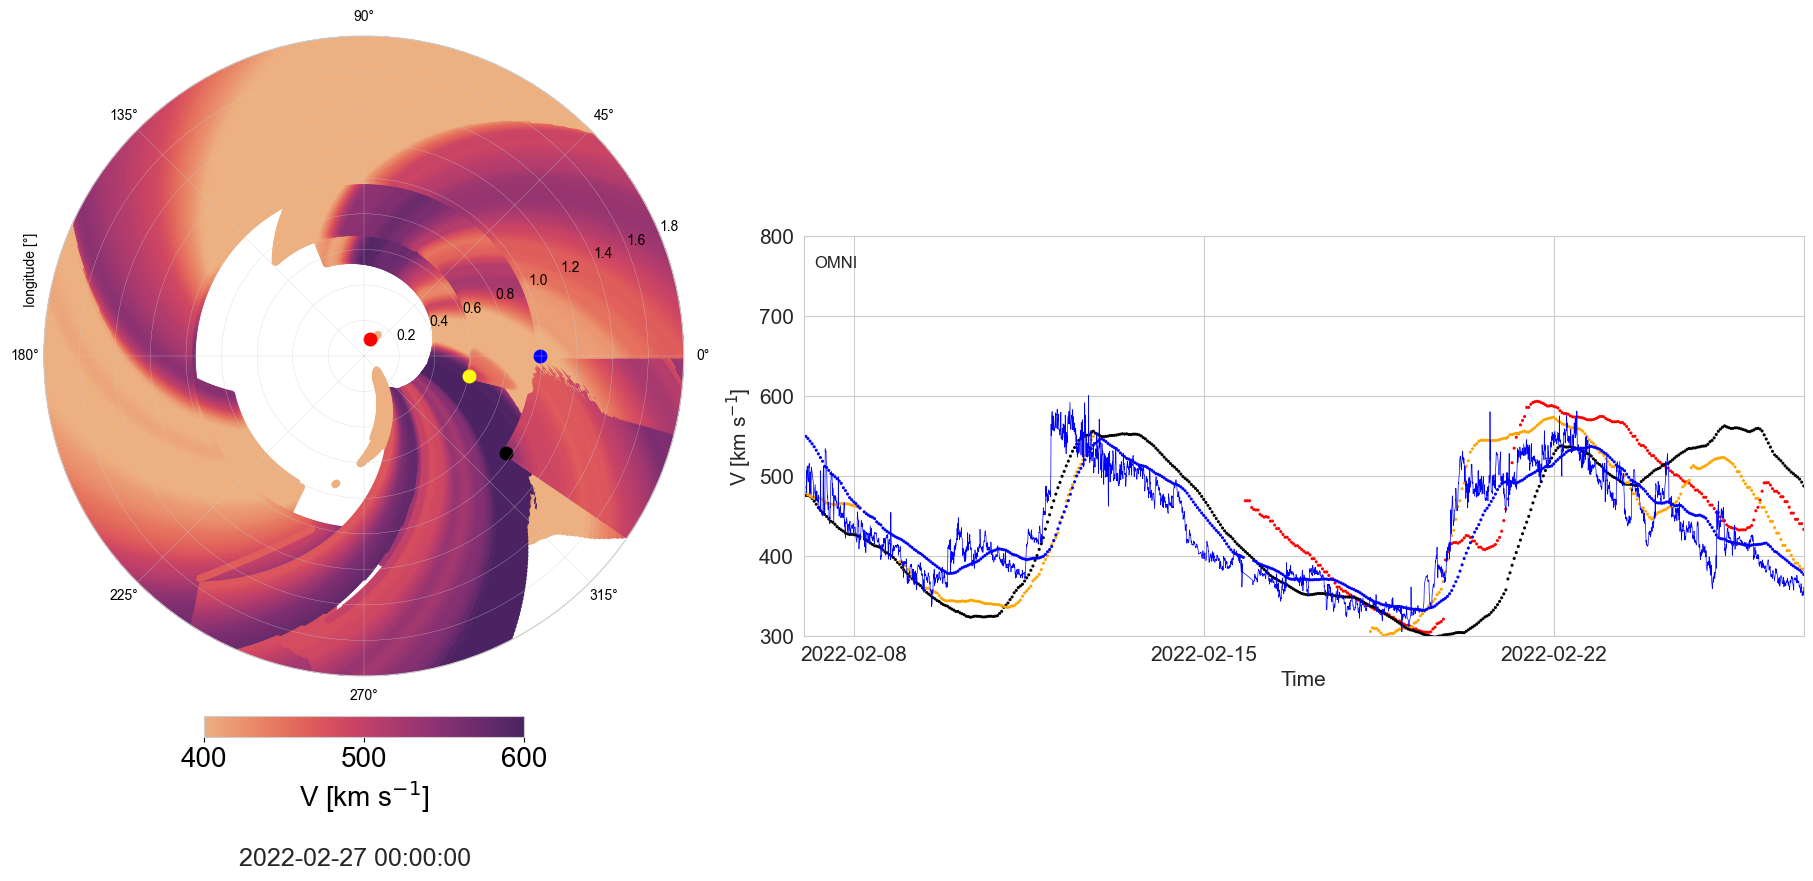

In [4]:
model.movie(observers=['OMNI'],rlim=1.8, plot_against_time=True, time_window='20d', cadence='48h', name='PAPERPLOT')

In [1]:
from P2D import P2D
import seaborn as sns
import matplotlib.pyplot as plt
# Set a single font size for everything
fontsize = 30

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "font.size": fontsize,          # Base font size for everything
        "axes.titlesize": fontsize,     # Axes title
        "axes.labelsize": fontsize,     # Axes labels
        "xtick.labelsize": fontsize,    # X ticks
        "ytick.labelsize": fontsize/1.5,    # Y ticks
        "legend.fontsize": fontsize*1.5,    # Legend text
        "figure.titlesize": fontsize,   # Figure title
        "figure.dpi": 100              # Figure quality
    }
)

timerange=['2022-6-5', '2022-6-27']
#timerange=['2022-1-1', '2022-5-27']
timerange=['2022-3-5', '2022-8-12'] # EXPLAINER PART 1
#timerange=['2022-7-10', '2022-12-12'] # EXPLAINER PART 2

spacecraft = ['OMNI', 
                            'STEREO-A',
                            'SolO', 
                            'PSP'] 
                            #'MAVEN']

model = P2D.P2D(input_data=spacecraft
                , timerange=timerange
                #, propagation_time='0.1d'
                , propagation_time='5d'
                , model_type='inelastic'
                , degree_resolution=0.5, smooth = '1d', seperate_models=True)#, coordinate_system='other')


# # Create polar figure
# fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={"projection": "polar"})

# # Plot your model
# #model.plot(rlim=1.8, fighandle=fig, axhandle=ax, variable_to_plot='V')

# ax.set_axis_off()

# # Customize legend
# labels = ['OMNI', 
#                             'STEREO-A',
#                             'SolO', 
#                             'PSP'] 
#                             #'MAVEN']
# colors = ['blue', 
#           'black', 
#           'yellow', 
#           'red'] 
#           #'darkred']

# # Create custom legend handles
# from matplotlib.lines import Line2D
# # Create custom legend handles with dots
# handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10) 
#            for color in colors]

# Add legend to plot
#ax.legend(handles, labels, loc='lower right', bbox_to_anchor=(1.5, -0.25), frameon=True, fontsize=fontsize)
#ax.legend(handles, labels, loc='lower right', bbox_to_anchor=(0.5, 0.4), frameon=True, fontsize=fontsize)

# ax.text(
#     0.98, 0.98, '(c)',
#     transform=ax.transAxes,
#     ha='right', va='top',
#     fontsize=18, fontweight='bold'
# )

# ax.text(
#     0.88, 0.72, 'R [AU]',
#     transform=ax.transAxes,
#     ha='right', va='top',
#     fontsize=14
# )

#plt.show()


propagating spacecraft data:   0%|          | 0/4 [00:00<?, ?it/s]

OMNI:   0%|          | 0/3841 [00:00<?, ?it/s]

STEREO-A:   0%|          | 0/3841 [00:00<?, ?it/s]

SolO:   0%|          | 0/3841 [00:00<?, ?it/s]

PSP:   0%|          | 0/3841 [00:00<?, ?it/s]

FIRST CUTTING OUT TIMESERIES FROM ['OMNI'] PERSPECTIVE
OMNI
OBSERVING FROM OMNI


  0%|          | 0/3841 [00:00<?, ?it/s]

Animating:   0%|          | 0/1281 [00:00<?, ?it/s]

c:\Users\14milosi\P2D\P2D\P2D.py:1043: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plotting_df['R_difference'] = (plotting_df['R'] - plotting_df['Start_R_of_parcel'])
c:\Users\14milosi\P2D\P2D\P2D.py:1044: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plotting_df['Radial_travel_time'] = (plotting_df.index - plotting_df['Start_time_of_parcel']).dt.total_seconds()/3600/24
c:\Users\14milosi\P2D\P2D\P2D.py:1043: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try us

mp4 file written to P2D_EXPLAINER_prop_5d_window_20d_37690_sc.mp4


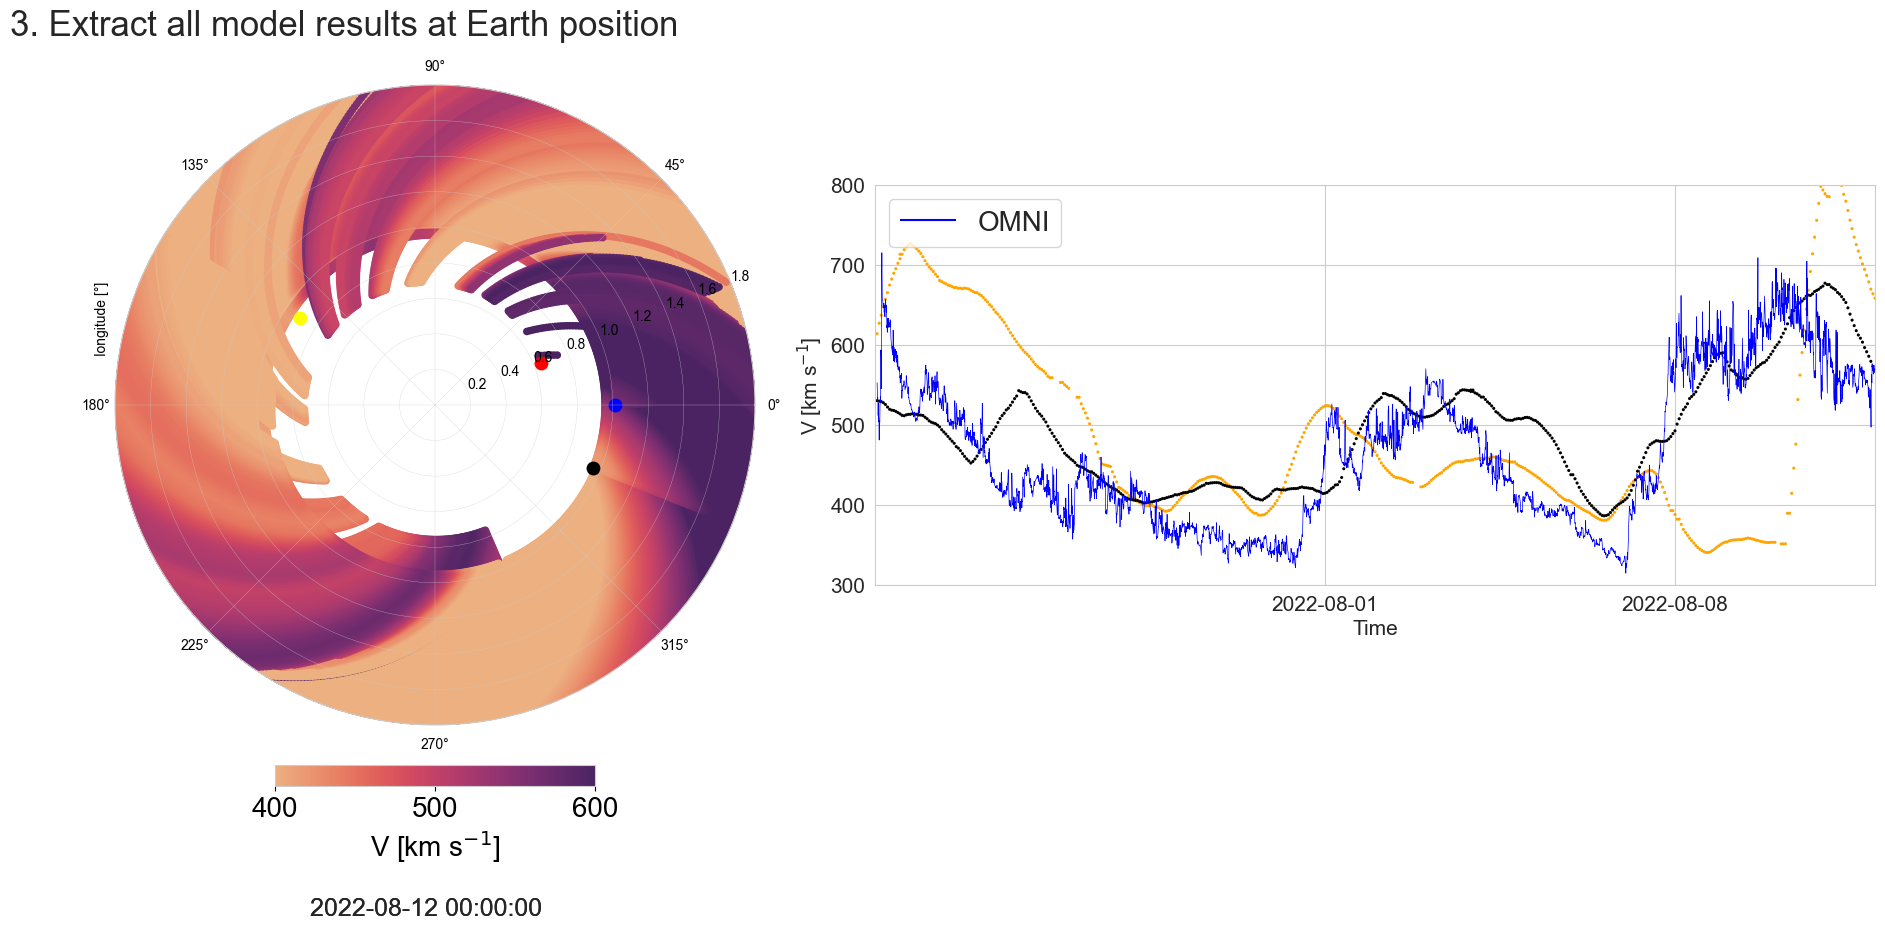

In [2]:
model.movie(observers=['OMNI'],rlim=1.8, plot_against_time=True, time_window='20d', cadence='3h', name='EXPLAINER')

In [1]:
import subprocess

input_file = "Combined Models.mp4"
output_file = "Combined_Models.mp4"

cmd = [
    "ffmpeg",
    "-i", input_file,
    "-c:v", "libx264",
    "-crf", "26",          # 23–28 (higher = smaller file)
    "-preset", "slow",
    "-tune", "animation",  # ideal for plots
    "-pix_fmt", "yuv420p",
    "-an",                 # remove audio completely
    output_file
]

subprocess.run(cmd, check=True)

CompletedProcess(args=['ffmpeg', '-i', 'Combined Models.mp4', '-c:v', 'libx264', '-crf', '26', '-preset', 'slow', '-tune', 'animation', '-pix_fmt', 'yuv420p', '-an', 'Combined_Models.mp4'], returncode=0)

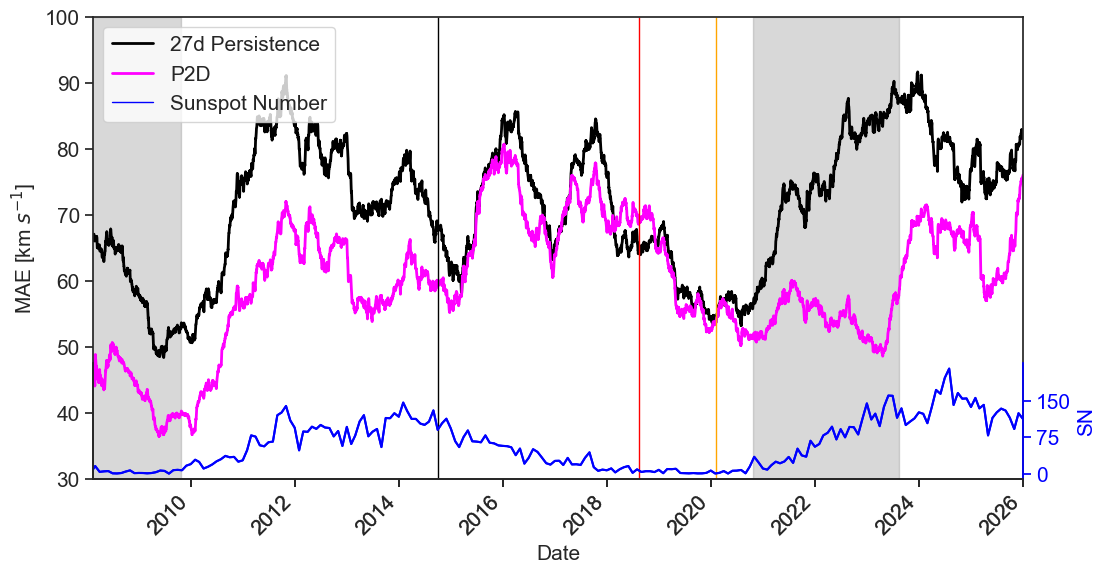

In [5]:


#  SINGLE


import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import seaborn as sns
from P2D import dataloader
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 15,    # Axis label size
        "xtick.labelsize": 15,   # X-axis tick label size
        "ytick.labelsize": 15,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Paper -> 1000
        "legend.fontsize": 15 # Size of legend
    }
)
SN = pd.read_csv('SN_m_tot_V2.0.csv', sep=';', names = ['year', 'month', 'Decimal Date', 'SN', 'SDE', '#', 'Indicator'])
SN['day'] =1
SN['Date'] = pd.to_datetime(SN[['year', 'month', 'day']])
SN[SN['SN']<0]=np.nan


# #time_series = model2.combined_model
# time_series_0 = pd.read_parquet('combined_model_superlong_2007_2008_1d_smooth.parquet')
# time_series_1 = pd.read_parquet('combined_model_superlong_2008_2015_1d_smooth.parquet')
# time_series_2 = pd.read_parquet('single_model_superlong.parquet')
# time_series_3 = pd.read_parquet('combined_model_superlong_2023_2026_1d_smooth.parquet')

# time_series_0 = time_series_0.loc[:time_series_1.index[0]]
# time_series_2 = time_series_2.loc[time_series_1.index[-1]:]
# time_series_3 = time_series_3.loc[time_series_2.index[-1]:]
# time_series = pd.concat([time_series_0, time_series_1, time_series_2, time_series_3]).drop_duplicates(keep='first')

# # BETTER PEAKS

time_series_0 = pd.read_parquet('P2D_2008_2015_2h_smooth.parquet')
time_series_1 = pd.read_parquet('P2D_2014_2023_2h_smooth.parquet')
time_series_2 = pd.read_parquet('P2D_2023_2026_2h_smooth.parquet')

time_series_1 = time_series_1.loc[time_series_0.index[-1]:]
time_series_2 = time_series_2.loc[time_series_1.index[-1]:]
time_series = pd.concat([time_series_0, time_series_1, time_series_2]).drop_duplicates(keep='first')

time_series.loc[time_series['N']>100, 'N'] = 100


#time_series =pd.read_parquet('single_model_superlong.parquet')
#time_series2 = pd.read_parquet('27_27d_persistence.parquet')
time_series2 = pd.read_parquet('27_27d_persistence_1h_smooth_whole_range.parquet')

#timeframe = ['2023-10-15', '2023-11-15']
timeframe = None
''
if timeframe is not None:
    time_series = time_series[timeframe:timeframe[1]]
    time_series2 = time_series2[timeframe:timeframe[1]]

start_time = time_series2.index.min().strftime('%Y-%m-%d-%H:%M')
end_time = time_series2.index.max().strftime('%Y-%m-%d-%H:%M')

SN = SN[(SN['Date']>start_time) & (SN['Date']<end_time)]

# Load spacecraft data
spacecraft_data = dataloader.load(spacecraft='OMNI', timerange=[start_time, end_time], cadence='1h')
spacecraft_data = spacecraft_data[~spacecraft_data.index.duplicated(keep='first')]



remove_cmes=False
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = time_series['Observer_SC']==spacecraft_ID(my_spacecraft[i], ID_number=True)
        mask2 = time_series2['Observer_SC']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)
            time_mask2 = (mask2.index < end) & (mask2.index > start)

            print(start, end, time_mask.sum())
            time_series[time_mask] = np.nan
            time_series2[time_mask2] = np.nan
            
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = spacecraft_data['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            spacecraft_data[time_mask] = np.nan


time_series['ΔV'] = time_series['V'] - time_series.index.map(spacecraft_data['V'])
time_series['V_MAE'] = abs(time_series['V'] - time_series.index.map(spacecraft_data['V']))
time_series['HITS'] = abs(time_series['V'] - time_series.index.map(spacecraft_data['V'])) < time_series['V_ERROR']

x = time_series['V'].sort_index()
y = x.index.map(spacecraft_data['V'])
mask = ~np.isnan(x) & ~np.isnan(y)
slope, intercept, r_value, p_value, std_err = linregress(x[mask], y[mask])

time_series2['ΔV'] = time_series2['V'] - time_series2.index.map(spacecraft_data['V'])
time_series2['V_MAE'] = abs(time_series2['V'] - time_series2.index.map(spacecraft_data['V']))
time_series2['HITS'] = abs(time_series2['V'] - time_series2.index.map(spacecraft_data['V'])) < time_series2['V_ERROR']

x = time_series2['V'].sort_index()
y = x.index.map(spacecraft_data['V'])
mask = ~np.isnan(x) & ~np.isnan(y)
slope, intercept, r_value2, p_value, std_err = linregress(x[mask], y[mask])


# Set up figure
fig, ax = plt.subplots(1,1,figsize=(12, 6))
import matplotlib.dates as mdates





time_series['AVERAGE_MAE'] = time_series['V_MAE'].rolling(window='300d').mean()
time_series2['AVERAGE_MAE'] = time_series2['V_MAE'].rolling(window='300d').mean()

time_series = time_series.iloc[1000:]
time_series2 = time_series2.iloc[1000:]

# sns.scatterplot(
#     data=time_series2, x=time_series2.index, y='AVERAGE_MAE', 
#     color= 'black', ax=ax, s=5, linewidth=0
# )

# sns.scatterplot(
#     data=time_series, x=time_series.index, y='AVERAGE_MAE', 
#     color= 'magenta', ax=ax, s=5, linewidth=0, label='P2D'
# )


sns.lineplot(
    data=time_series2, x=time_series2.index, y='AVERAGE_MAE', 
    color= 'black', ax=ax, linewidth=2, label='27d Persistence'
)

sns.lineplot(
    data=time_series, x=time_series.index, y='AVERAGE_MAE', 
    color= 'magenta', ax=ax, linewidth=2, label='P2D'
)

sns.lineplot(
    data=time_series*0, x=time_series.index, y='AVERAGE_MAE', 
    color= 'blue', ax=ax, linewidth=1, label='Sunspot Number'
)




# Get main axis position
pos = ax.get_position()

# Create a new axis with 1/3 height
ax_sn = fig.add_axes([
    pos.x0,
    pos.y0,
    pos.width,
    pos.height / 4
], sharex=ax)

sns.lineplot(
    data=SN,
    x='Date',
    y='SN',
    color='blue',
    ax=ax_sn
)

# Right-side ticks only
ax_sn.yaxis.tick_right()
ax_sn.yaxis.set_label_position("right")
ax_sn.set_ylabel("SN")

# Clean up
ax_sn.spines['top'].set_visible(False)
#ax_sn.spines['left'].set_visible(False)
#ax_sn.spines['bottom'].set_visible(False)



sns.lineplot(
    data=SN, x=SN['Date'], y='SN', 
    color= 'blue', ax=ax_sn#, label='SN'
)


# Beautify time axis
ax.xaxis.set_major_locator(mdates.AutoDateLocator())  # or WeekLocator(), AutoDateLocator()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))#-%m-%d'))  # or '%b %Y' for abbreviated months
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')  # Rotate for readability
plt.setp(ax_sn.get_xticklabels(), rotation=45, ha='right')  # Rotate for readability


ax.vlines(pd.to_datetime('2018-08-12'), 0, 100, color='red', linewidth=1)
ax.vlines(pd.to_datetime('2020-02-10'), 0, 100, color='orange', linewidth=1)
ax.vlines(pd.to_datetime('2014-10-1'), 0, 100, color='black', linewidth=1)



ax.set_xlabel('Date')
ax.set_ylabel(r'MAE [km $s^{-1}$]')
ax.set_xlim(time_series.index.min(), time_series.index.max())


ax.set_ylim(30,100)
#ax_sn.set_ylim(0,600)
ax_sn.set_yticks((0, 75, 150))
#ax_sn.set_xticklabels(())
ax_sn.set_xlabel((''))
ax_sn.spines['right'].set_color('blue')

# Right y-axis ticks and tick labels
ax_sn.tick_params(axis='y', which='both',
                  right=True,
                  colors='blue')

# Right y-axis label (if present)
ax_sn.yaxis.label.set_color('blue')
ax_sn.patch.set_alpha(0)


ax.legend(loc='upper left')

#ax.grid()

first_stream = pd.to_datetime(['2007-02-01', '2009-10-22'])
second_stream = pd.to_datetime(['2020-10-22', '2023-08-12'])
alpha=0.3
ax.fill_between(x = first_stream, y1 = 30, y2 = 100, color = 'grey', alpha=alpha)
ax.fill_between(x = second_stream, y1 = 30, y2 = 100, color = 'grey', alpha=alpha)





#plt.tight_layout()
plt.show()


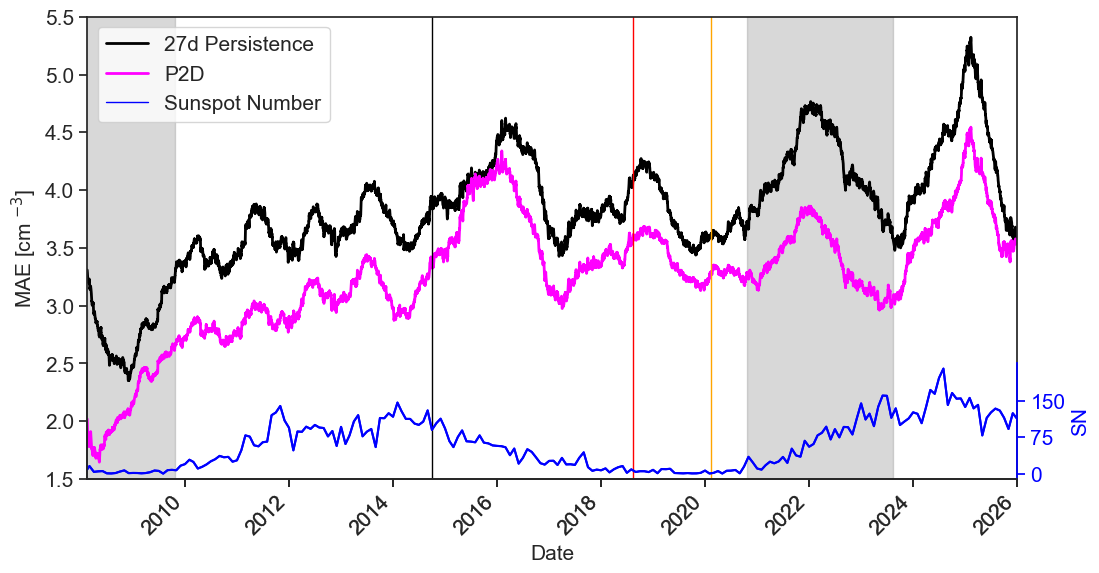

In [11]:


#  DENSITY


import matplotlib.pyplot as plt
import pandas as pd
import matplotlib
import seaborn as sns
from P2D import dataloader
from P2D.utils import spacecraft_ID
import numpy as np
from scipy.stats import linregress

sns.set(
    style="ticks",
    palette="muted",
    rc={
        "axes.labelsize": 15,    # Axis label size
        "xtick.labelsize": 15,   # X-axis tick label size
        "ytick.labelsize": 15,   # Y-axis tick label size
        "font.size": 13,         # Overall font size
        "figure.dpi": 100,        # Paper -> 1000
        "legend.fontsize": 15 # Size of legend
    }
)
SN = pd.read_csv('SN_m_tot_V2.0.csv', sep=';', names = ['year', 'month', 'Decimal Date', 'SN', 'SDE', '#', 'Indicator'])
SN['day'] =1
SN['Date'] = pd.to_datetime(SN[['year', 'month', 'day']])
SN[SN['SN']<0]=np.nan


# #time_series = model2.combined_model
# time_series_0 = pd.read_parquet('combined_model_superlong_2007_2008_1d_smooth.parquet')
# time_series_1 = pd.read_parquet('combined_model_superlong_2008_2015_1d_smooth.parquet')
# time_series_2 = pd.read_parquet('single_model_superlong.parquet')
# time_series_3 = pd.read_parquet('combined_model_superlong_2023_2026_1d_smooth.parquet')

# time_series_0 = time_series_0.loc[:time_series_1.index[0]]
# time_series_2 = time_series_2.loc[time_series_1.index[-1]:]
# time_series_3 = time_series_3.loc[time_series_2.index[-1]:]
# time_series = pd.concat([time_series_0, time_series_1, time_series_2, time_series_3]).drop_duplicates(keep='first')

# # BETTER PEAKS

time_series_0 = pd.read_parquet('P2D_2008_2015_2h_smooth.parquet')
time_series_1 = pd.read_parquet('P2D_2014_2023_2h_smooth.parquet')
time_series_2 = pd.read_parquet('P2D_2023_2026_2h_smooth.parquet')

time_series_1 = time_series_1.loc[time_series_0.index[-1]:]
time_series_2 = time_series_2.loc[time_series_1.index[-1]:]
time_series = pd.concat([time_series_0, time_series_1, time_series_2]).drop_duplicates(keep='first')

time_series.loc[time_series['N']>100, 'N'] = 100


#time_series =pd.read_parquet('single_model_superlong.parquet')
#time_series2 = pd.read_parquet('27_27d_persistence.parquet')
time_series2 = pd.read_parquet('27_27d_persistence_1h_smooth_whole_range.parquet')

#timeframe = ['2023-10-15', '2023-11-15']
timeframe = None
''
if timeframe is not None:
    time_series = time_series[timeframe:timeframe[1]]
    time_series2 = time_series2[timeframe:timeframe[1]]

start_time = time_series2.index.min().strftime('%Y-%m-%d-%H:%M')
end_time = time_series2.index.max().strftime('%Y-%m-%d-%H:%M')

SN = SN[(SN['Date']>start_time) & (SN['Date']<end_time)]

# Load spacecraft data
spacecraft_data = dataloader.load(spacecraft='OMNI', timerange=[start_time, end_time], cadence='1h')
spacecraft_data = spacecraft_data[~spacecraft_data.index.duplicated(keep='first')]



remove_cmes=False
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = time_series['Observer_SC']==spacecraft_ID(my_spacecraft[i], ID_number=True)
        mask2 = time_series2['Observer_SC']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)
            time_mask2 = (mask2.index < end) & (mask2.index > start)

            print(start, end, time_mask.sum())
            time_series[time_mask] = np.nan
            time_series2[time_mask2] = np.nan
            
if remove_cmes:
    cmes = pd.read_excel('HELIO4CAST_ICMECAT_v23 (1).xlsx')

    spacecraft = ['Wind', 'STEREO-A', 'SolarOrbiter', 'PSP']
    my_spacecraft = ['OMNI', 'STEREO-A', 'SolO', 'PSP']

    for i, sc in enumerate(spacecraft):
        print(sc, ' => ', my_spacecraft[i])
        start_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['icme_start_time']).reset_index()['icme_start_time'] - pd.Timedelta(value='16h')
        end_times = pd.to_datetime(cmes.loc[cmes['sc_insitu']==sc]['mo_end_time']).reset_index()['mo_end_time'] + pd.Timedelta(value='16h')

        mask = spacecraft_data['Spacecraft_ID']==spacecraft_ID(my_spacecraft[i], ID_number=True)

        for j in range(len(start_times)):
            
            start = start_times[j].round("h").tz_localize(None)
            end = end_times[j].round("h").tz_localize(None)

            time_mask = (mask.index < end) & (mask.index > start)


            print(start, end, time_mask.sum())
            spacecraft_data[time_mask] = np.nan


time_series['ΔV'] = time_series['N'] - time_series.index.map(spacecraft_data['N'])
time_series['V_MAE'] = abs(time_series['N'] - time_series.index.map(spacecraft_data['N']))
time_series['HITS'] = abs(time_series['N'] - time_series.index.map(spacecraft_data['N'])) < time_series['V_ERROR']

x = time_series['N'].sort_index()
y = x.index.map(spacecraft_data['N'])
mask = ~np.isnan(x) & ~np.isnan(y)
slope, intercept, r_value, p_value, std_err = linregress(x[mask], y[mask])

time_series2['ΔV'] = time_series2['N'] - time_series2.index.map(spacecraft_data['N'])
time_series2['V_MAE'] = abs(time_series2['N'] - time_series2.index.map(spacecraft_data['N']))
time_series2['HITS'] = abs(time_series2['N'] - time_series2.index.map(spacecraft_data['N'])) < time_series2['V_ERROR']

x = time_series2['N'].sort_index()
y = x.index.map(spacecraft_data['N'])
mask = ~np.isnan(x) & ~np.isnan(y)
slope, intercept, r_value2, p_value, std_err = linregress(x[mask], y[mask])


# Set up figure
fig, ax = plt.subplots(1,1,figsize=(12, 6))
import matplotlib.dates as mdates





time_series['AVERAGE_MAE'] = time_series['V_MAE'].rolling(window='300d').mean()
time_series2['AVERAGE_MAE'] = time_series2['V_MAE'].rolling(window='300d').mean()

time_series = time_series.iloc[1000:]
time_series2 = time_series2.iloc[1000:]

# sns.scatterplot(
#     data=time_series2, x=time_series2.index, y='AVERAGE_MAE', 
#     color= 'black', ax=ax, s=5, linewidth=0
# )

# sns.scatterplot(
#     data=time_series, x=time_series.index, y='AVERAGE_MAE', 
#     color= 'magenta', ax=ax, s=5, linewidth=0, label='P2D'
# )


sns.lineplot(
    data=time_series2, x=time_series2.index, y='AVERAGE_MAE', 
    color= 'black', ax=ax, linewidth=2, label='27d Persistence'
)

sns.lineplot(
    data=time_series, x=time_series.index, y='AVERAGE_MAE', 
    color= 'magenta', ax=ax, linewidth=2, label='P2D'
)

sns.lineplot(
    data=time_series*0, x=time_series.index, y='AVERAGE_MAE', 
    color= 'blue', ax=ax, linewidth=1, label='Sunspot Number'
)




# Get main axis position
pos = ax.get_position()

# Create a new axis with 1/3 height
ax_sn = fig.add_axes([
    pos.x0,
    pos.y0,
    pos.width,
    pos.height / 4
], sharex=ax)

sns.lineplot(
    data=SN,
    x='Date',
    y='SN',
    color='blue',
    ax=ax_sn
)

# Right-side ticks only
ax_sn.yaxis.tick_right()
ax_sn.yaxis.set_label_position("right")
ax_sn.set_ylabel("SN")

# Clean up
ax_sn.spines['top'].set_visible(False)
#ax_sn.spines['left'].set_visible(False)
#ax_sn.spines['bottom'].set_visible(False)



sns.lineplot(
    data=SN, x=SN['Date'], y='SN', 
    color= 'blue', ax=ax_sn#, label='SN'
)


# Beautify time axis
ax.xaxis.set_major_locator(mdates.AutoDateLocator())  # or WeekLocator(), AutoDateLocator()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))#-%m-%d'))  # or '%b %Y' for abbreviated months
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')  # Rotate for readability
plt.setp(ax_sn.get_xticklabels(), rotation=45, ha='right')  # Rotate for readability


ax.vlines(pd.to_datetime('2018-08-12'), 0, 10, color='red', linewidth=1)
ax.vlines(pd.to_datetime('2020-02-10'), 0, 10, color='orange', linewidth=1)
ax.vlines(pd.to_datetime('2014-10-1'), 0, 10, color='black', linewidth=1)



ax.set_xlabel('Date')
ax.set_ylabel(r'MAE [cm $^{-3}$]')
ax.set_xlim(time_series.index.min(), time_series.index.max())


ax.set_ylim(1.5,5.5)
#ax_sn.set_ylim(0,600)
ax_sn.set_yticks((0, 75, 150))
#ax_sn.set_xticklabels(())
ax_sn.set_xlabel((''))
ax_sn.spines['right'].set_color('blue')

# Right y-axis ticks and tick labels
ax_sn.tick_params(axis='y', which='both',
                  right=True,
                  colors='blue')

# Right y-axis label (if present)
ax_sn.yaxis.label.set_color('blue')
ax_sn.patch.set_alpha(0)


ax.legend(loc='upper left')

#ax.grid()

first_stream = pd.to_datetime(['2007-02-01', '2009-10-22'])
second_stream = pd.to_datetime(['2020-10-22', '2023-08-12'])
alpha=0.3
ax.fill_between(x = first_stream, y1 = 0, y2 = 10, color = 'grey', alpha=alpha)
ax.fill_between(x = second_stream, y1 = 0, y2 = 10, color = 'grey', alpha=alpha)





#plt.tight_layout()
plt.show()


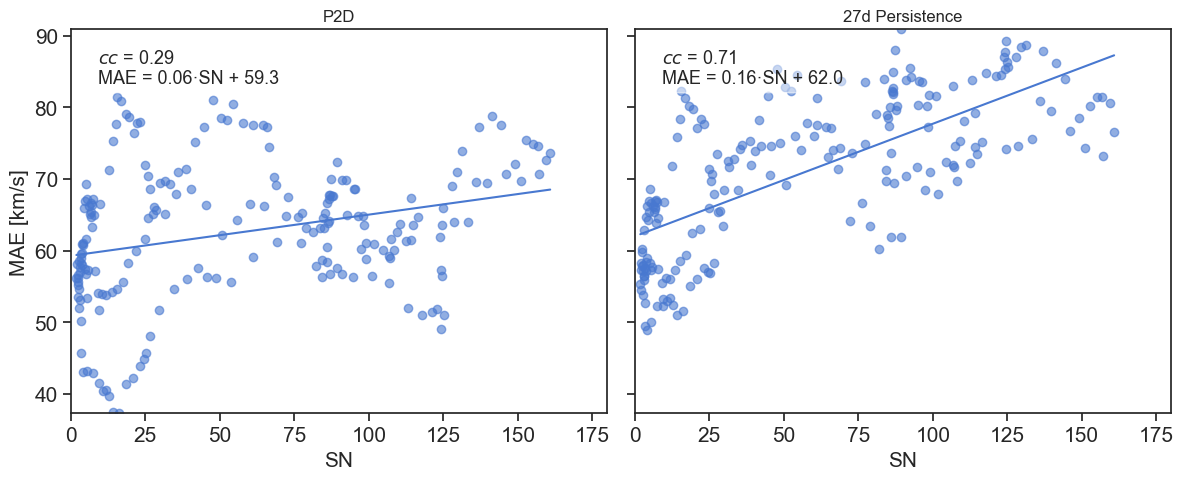

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress, spearmanr

# --- Remove duplicate index entries ---
#SN['Date'] = pd.to_datetime(SN['Date']) 
#SN.set_index('Date', inplace= True)
SN = SN[~SN.index.duplicated(keep='first')]
time_series = time_series[~time_series.index.duplicated(keep='first')]
time_series2 = time_series2[~time_series2.index.duplicated(keep='first')]

# --- Align datasets ---
df1 = SN[['SN']].join(time_series[['AVERAGE_MAE']], how='inner').dropna()
df2 = SN[['SN']].join(time_series2[['AVERAGE_MAE']], how='inner').dropna()

# --- Compute global y-limits so both panels share identical scaling ---
ymin = min(df1['AVERAGE_MAE'].min(), df2['AVERAGE_MAE'].min())
ymax = max(df1['AVERAGE_MAE'].max(), df2['AVERAGE_MAE'].max())

# --- Create figure with shared y-axis ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# ========================
# Panel 1
# ========================
slope1, intercept1, r1, p1, _ = linregress(df1['SN'], df1['AVERAGE_MAE'])
rho1, _ = spearmanr(df1['SN'], df1['AVERAGE_MAE'])

x1 = np.linspace(df1['SN'].min(), df1['SN'].max(), 200)
y1 = slope1 * x1 + intercept1

axes[0].scatter(df1['SN'], df1['AVERAGE_MAE'], alpha=0.6)
axes[0].plot(x1, y1)
axes[0].set_title("P2D")
axes[0].set_xlabel("SN")
axes[0].set_ylabel("MAE [km/s]")
axes[0].set_ylim(ymin, ymax)

axes[0].text(
    0.05, 0.95,
    f"$cc$ = {r1:.2f}\nMAE = {slope1:.2f}·SN + {intercept1:.1f}",
    transform=axes[0].transAxes,
    verticalalignment='top',
    bbox=dict(boxstyle="round", alpha=0.5, color='white')
)

# ========================
# Panel 2
# ========================
slope2, intercept2, r2, p2, _ = linregress(df2['SN'], df2['AVERAGE_MAE'])
rho2, _ = spearmanr(df2['SN'], df2['AVERAGE_MAE'])

x2 = np.linspace(df2['SN'].min(), df2['SN'].max(), 200)
y2 = slope2 * x2 + intercept2

axes[1].scatter(df2['SN'], df2['AVERAGE_MAE'], alpha=0.6)
axes[1].plot(x2, y2)
axes[1].set_title("27d Persistence")
axes[1].set_xlabel("SN")
axes[1].set_xlim(0,180)
axes[0].set_xlim(0,180)
axes[1].set_ylim(ymin, ymax)

axes[1].text(
    0.05, 0.95,
    f"$cc$ = {r2:.2f}\nMAE = {slope2:.2f}·SN + {intercept2:.1f}",
    transform=axes[1].transAxes,
    verticalalignment='top',
    bbox=dict(boxstyle="round", alpha=0.5, color='white')
)

plt.tight_layout()
plt.show()